<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_IoTAnomalyDetection_Chandrasekhar2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum autoencoder + trainable quantum kernel for IoT anomaly detection: Chandrasekhar et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Swathi Chandrasekhar, Shiva Raj Pokhrel, Swati Kumari and Navneet Singh, "Modeling Quantum Autoencoder Trainable Kernel
> for IoT Anomaly Detection", arXiv:2511.21932 (2025). https://arxiv.org/abs/2511.21932

The paper publishes no code. Everything below is written from its description, with the software stack the paper names
(Qiskit, `RawFeatureVector`, `RealAmplitudes`, Qiskit Machine Learning's trainable quantum kernel and `QSVC`, Aer
simulators). Where the paper is silent, the choice is made explicit in the table "What follows the paper and what had to be
chosen" and marked `# CHOICE:` in the code.

**What the notebook does.** It downloads three public network-traffic data sets (Bot-IoT, IoT-23 and KDD Cup 1999, the three
the paper uses), applies the paper's three-stage preprocessing (z-score, L2 normalisation, zero padding to a power of two),
loads every traffic record as the *amplitudes* of an `n_q`-qubit quantum state (`RawFeatureVector`), trains a **quantum
autoencoder** (a `RealAmplitudes` encoder followed by a SWAP test; loss = probability of reading 1 on the SWAP-test qubit)
with COBYLA on mini-batches, reads the probability distribution of the latent qubits as the compressed record, trains a
**quantum kernel with trainable parameters** on those latent vectors with SPSA (SVC dual loss), and classifies with a
**QSVC**. All of this is run twice, once on an ideal simulator and once with **depolarizing noise** in an exact density-matrix
simulator that is checked against Qiskit Aer (the paper's "noise as implicit regulariser" claim). A random forest and an RBF-SVM on exactly the same inputs are
the classical baselines. The last sections put the paper's Table I, Table II and Table IV numbers next to the notebook's and
give a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit versions; if Colab asks you to restart the session, restart and run all again. No GPU and no quantum-cloud
account are needed. The datasets are public (the Hugging Face token only matters if a mirror is ever gated; see the data
section).

**Runtime.** With `FAST_MODE = True` the notebook is a class demo (about 10 minutes on a laptop CPU: 60 records per class and
data set, short optimiser budgets, two seeds). With `FAST_MODE = False` it uses 200 records per class, longer COBYLA and SPSA
budgets, five seeds (three for the noisy runs) and a calibration-based emulation of the paper's `ibm_fez` run (roughly 45 minutes on an idle laptop CPU; the committed run took about 99 minutes on a heavily shared machine).
The runtime of the committed run is printed at the end of the notebook.

**What you get at the end.** Train/test accuracy, weighted precision/recall/F1 (the paper's convention) for the ideal and
the noisy QAE-QSVC on the three data sets, loss curves with 95 % bands (Table I, Fig. 2), the coefficient of variation of
the loss (Fig. 4), confusion matrices, latent-space scatter plots, a classical comparison, an ablation of the kernel training,
and an honest verdict for every claim of the paper that can be tested here.

## The paper in one page

**Problem.** Detect anomalous (attack) traffic in IoT and generic network data. The authors argue that classical deep
autoencoders are too heavy for edge devices and propose a compact quantum pipeline.

**Decision.** Normal versus anomalous (attack) per traffic record.

**Method (Fig. 1, Section I).**
1. *Preprocessing:* z-score each feature (mean and standard deviation from the training data), L2-normalise every record to
   unit length, pad with zeros to length $2^{n_q}$ with $n_q=\lceil\log_2 d\rceil$ ($d$ = number of features).
2. *Amplitude encoding:* `RawFeatureVector(2**n_q)` loads the record as $|\psi(x)\rangle=\sum_i x_i|i\rangle$ on $n_q$ qubits.
   No classical dimensionality reduction (no PCA): all compression happens inside the quantum autoencoder.
3. *Quantum autoencoder (QAE):* $(n_l+2n_t+1)$ qubits: a latent register of $n_l$ qubits, "trash" register A of $n_t$ qubits,
   a reference register B of $n_t$ qubits in $|0\rangle$ and one auxiliary qubit; $n_q=n_l+n_t$. An encoder
   $U_{enc}(\theta)=\prod_{r=1}^{n}[U_{ent}\,U_{rot}(\theta_r)]$ (`RealAmplitudes`, RY rotations and a linear chain of CNOTs,
   $n\times(n_l+n_t)$ parameters) acts on the first $n_l+n_t$ qubits. A **SWAP test** between trash A and trash B measures how
   close the trash is to $|0\ldots0\rangle$; the loss is the probability of measuring $|1\rangle$ on the auxiliary qubit.
   Training: **COBYLA** on randomly drawn mini-batches (loss mean, standard deviation across batches and the 95 % band
   $\mu\pm1.96\sigma$ are logged).
4. *Latent features:* after training, run the encoder only and read the probability distribution over the $n_l$ latent qubits.
5. *Trainable quantum kernel:* $K(z_i,z_j;\phi)=|\langle0|\Phi^\dagger(z_j,\phi)\Phi(z_i,\phi)|0\rangle|^2$ (compute-uncompute
   fidelity), parameters $\phi$ trained with **SPSA** on the QSVC (SVC dual) loss
   $\tfrac12\alpha^TK\alpha-\sum\alpha_i$.
6. *Classifier:* **QSVC** with the trained kernel.
7. *Noise:* the same pipeline under depolarizing noise in an Aer simulator, and a small run on IBM `ibm_fez` hardware.

**Data.** Bot-IoT, IoT-23, KDD99 (sizes, features and split are not given).

**Claims to check.**
* Table II (Aer): test accuracy above 92 % on all three data sets; with depolarizing noise above 95 % on most:
  Bot-IoT 92.42 % ideal / 95.45 % noisy, IoT-23 99.50 % / 97.37 %, KDD99 97.66 % / 98.33 % (test accuracy); test F1
  0.9294 / 0.9543, 0.9268 / 0.9222, 0.9766 / 0.9836.
* Table I: QAE loss statistics (average loss standard deviation 0.017 to 0.030, 95 % bands about 0.15 to 0.37).
* Fig. 2: Bot-IoT ideal loss floor about 0.20, noisy about 0.30; for IoT-23 and KDD99 noise stabilises the oscillations.
* "Moderate depolarizing noise acts as implicit regularisation" (noisy generalisation as good or better than ideal).
* Table IV: beats the QAE + one-class SVM of Hdaib et al. on KDD99 and IoT-23 (their numbers are quoted, not rerun).
* Table III: 83.3 % and 84.4 % accuracy on real `ibm_fez` hardware (reduced samples) for Bot-IoT and IoT-23.
* "Practical quantum advantage" in the abstract (no classical comparison is shown in the paper).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data sets | Bot-IoT, IoT-23, KDD99; sizes and versions not given | Bot-IoT (Hugging Face mirror `masoltani/bot-iot`, first row group), IoT-23 conn.log table (`19kmunz/iot-23-preprocessed`, 819,024 flows), KDD Cup 1999 10 % file; labels binarised to normal / attack |
| Sample size and split | not stated (Table II implies a few hundred test records) | `N_PER_CLASS` records per class (balanced; attacks drawn in the data set's own mix), stratified 80 : 20 split, `SEED = 42` |
| Features | all features, no dimensionality reduction | identifier/time columns dropped, categorical codes ordinal, constant columns dropped; **cap of `MAX_NQ = 5` qubits (32 amplitudes)**: if more than 32 features remain, the 32 best by ANOVA F-score on the training split are kept (CHOICE, needed to keep the density-matrix noise simulation feasible) |
| Preprocessing | z-score, L2 norm, zero padding to $2^{n_q}$ | the same, plus a signed `log1p` on the raw values first (CHOICE: heavy-tailed byte and packet counts otherwise dominate the amplitude vector); every transform fitted on the training split only |
| Latent size $n_l$, trash size $n_t$ | not stated | $n_l=2$ (4 latent probabilities), $n_t=n_q-n_l$ |
| Encoder | `RealAmplitudes`, $n$ repetitions, $n(n_l+n_t)$ parameters | `real_amplitudes(n_q, reps=4, entanglement="linear", skip_final_rotation_layer=True)` so that the parameter count is exactly $4n_q$ as in the paper's formula |
| QAE loss and training | P(aux = 1) of the SWAP test, COBYLA, mini-batches | the same; $B$ batches of $b$ records per COBYLA evaluation (values in the config cell), loss computed exactly (infinite shots) |
| Latent features | probabilities over the $n_l$ latent qubits | the same (4 numbers per record), scaled to $[0,\pi]$ with the training split |
| Kernel feature map $\Phi(z,\phi)$ | not given | 4 qubits: trainable layer RY($\phi_i$) RZ($\phi_{4+i}$) on every qubit, then `zz_feature_map(4, reps=2, entanglement="linear")` carrying the data; 8 trainable parameters |
| Kernel fidelity | `ComputeUncompute`, finite shots | exact (statevector) in the ideal run, exact noisy probabilities (density matrix) in the noisy run |
| Kernel training | SPSA, SVC dual loss | `QuantumKernelTrainer` with `SPSA` (constant gains) and `SVCLoss(C=1)` on a stratified subset of the training split |
| QSVC regularisation $C$ | not stated | chosen from `C_GRID` on a validation split carved out of the training split |
| Noise model | "depolarizing", strength not stated | 1-qubit depolarizing $p_1=0.001$ on RY/SX/X/H, 2-qubit depolarizing $p_2=0.01$ on CX; the amplitude-encoding block is ideal (state preparation of an arbitrary vector is not decomposed into noisy gates) |
| Hardware (`ibm_fez`) | Table III, reduced samples | not reachable here; a cell runs only if `IBM_TOKEN` is set, otherwise the noisy-simulator run stands in |
| Baselines | none in the paper (only a quote of Hdaib et al.) | random forest and RBF-SVM on the same amplitude vectors and on the same latent features |
| Metrics | accuracy and weighted precision / recall / F1 (recall equals accuracy in Table II) | the same, plus attack-as-positive confusion matrices |

In [1]:
# Install pinned, Colab-compatible versions only when needed (Colab, or a missing package locally).
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _need_install():
    try:
        import qiskit, qiskit_machine_learning, qiskit_aer
        return not (qiskit.__version__.startswith("2.") and qiskit_machine_learning.__version__.startswith("0.9"))
    except Exception:
        return True
if IN_COLAB or _need_install():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                    "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "sympy", "huggingface_hub", "pyarrow", "requests"], check=False)
    print("packages installed; if Colab asks for a session restart, restart and run all again")
else:
    print("pinned packages already available")

pinned packages already available


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo (about 10 minutes). False: larger samples, longer optimiser budgets, five seeds.
SEED      = 42              # CHOICE: the paper reports no seed
IBM_TOKEN = ""              # optional: the real-hardware cell (paper: ibm_fez) runs only if a token is set; leave empty to skip it
N_THREADS = 2               # threads for the Aer density-matrix simulator

DATA_DIR      = "qc175_data"
DATASETS      = ["Bot-IoT", "IoT-23", "KDD99"]
HF_BOT        = ("masoltani/bot-iot", "balanced_dataset.parquet")                       # public BoT-IoT mirror (first row group is read)
HF_IOT23      = ["19kmunz/iot-23-preprocessed", "yashika0998/iot-23-preprocessed", "pradnyap/iot-23-preprocessed"]   # public IoT-23 mirrors
KDD_URLS      = ["https://ndownloader.figshare.com/files/5976042",                       # scikit-learn's mirror of kddcup.data_10_percent
                 "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]
NSL_KDD_FALLBACK = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"]   # used only if both KDD99 mirrors fail
POOL_CAP      = 3000        # CHOICE: cache at most this many Bot-IoT records per sub-category / 30,000 IoT-23 flows per class

# ---- what the paper fixes ----
NL_QUBITS     = 2           # CHOICE: the paper does not give n_l; 2 latent qubits -> 4 latent probabilities
ENC_REPS      = 4           # CHOICE: the paper's "n repetitions"; n(n_l + n_t) = 4 n_q encoder parameters
LOG1P         = True        # CHOICE: signed log1p before the z-score (paper: plain z-score)
MAX_NQ        = 5           # CHOICE: at most 5 data qubits (32 amplitudes); the SWAP-test circuit then has up to 9 qubits
TEST_SIZE     = 0.20        # CHOICE: split not given in the paper
VAL_FRACTION  = 0.25        # validation share of the training split, used only to choose C of the QSVC
KERNEL_REPS   = 2           # CHOICE: ZZ feature-map repetitions of the kernel circuit
C_GRID        = [0.1, 1.0, 10.0, 100.0]
SPSA_LR, SPSA_C = 0.05, 0.1 # CHOICE: constant SPSA gains (learning rate, perturbation); picked on a small pilot run
P1_ERR, P2_ERR = 0.001, 0.01  # CHOICE: depolarizing strengths (paper: "moderate", not stated)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    N_PER_CLASS = 60                     # records per class (120 -> 96 training / 24 test)
    QAE_BATCHES, QAE_BATCH, QAE_MAXITER = 3, 16, 80          # ideal QAE: batches per evaluation, records per batch, COBYLA evaluations
    SPSA_ITERS, KERNEL_M = 20, 40        # ideal kernel training: SPSA iterations, training subset size
    N_SEEDS, N_NOISY_SEEDS = 2, 1        # repeated ideal runs / repeated noisy runs for mean +- std (the same budgets are used with and without noise)
else:
    N_PER_CLASS = 200                    # 400 -> 320 training / 80 test
    QAE_BATCHES, QAE_BATCH, QAE_MAXITER = 4, 32, 300
    SPSA_ITERS, KERNEL_M = 40, 60
    N_SEEDS, N_NOISY_SEEDS = 5, 3
RUN_FAKE_FEZ = not FAST_MODE            # emulate the paper's ibm_fez experiment (Table III) with FakeFez calibration data (set-up takes minutes)
FEZ_N_TRAIN, FEZ_N_TEST, FEZ_SHOTS = 12, 6, 1024   # CHOICE: reduced samples, as in the paper
# Budgets of the paper itself (not reachable on a laptop CPU): Table II times of 8.4e4 to 1.6e5 seconds per data set.
print("FAST_MODE =", FAST_MODE, "| records per class:", N_PER_CLASS, "| QAE evaluations:", QAE_MAXITER, "| SPSA iterations:", SPSA_ITERS, "| seeds (ideal / noisy):", N_SEEDS, "/", N_NOISY_SEEDS)

FAST_MODE = False | records per class: 200 | QAE evaluations: 300 | SPSA iterations: 40 | seeds (ideal / noisy): 5 / 3


In [3]:
import os, time, json, math, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, zz_feature_map
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.kernels import TrainableFidelityStatevectorKernel
from qiskit_machine_learning.kernels.algorithms import QuantumKernelTrainer
from qiskit_machine_learning.utils.loss_functions import SVCLoss
from qiskit_machine_learning.optimizers import COBYLA, SPSA
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()

# Hugging Face token: the three mirrors used here are public, so None works. If a mirror is ever gated, add your own token as the
# Colab secret HF_TOKEN (Settings > Secrets). Never type a token into the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The three data sets

All three data sets are public and are downloaded here, then cached in `DATA_DIR`:

* **Bot-IoT** (UNSW Canberra, an IoT botnet testbed): flow records with 40 columns; the Hugging Face mirror stores 7.5 million
  rows in 8 row groups and we read only the first row group (about one million flows, 98 % attacks). Labels: `attack`
  (0/1), `category` (Normal, DDoS, DoS, Reconnaissance, Theft) and `subcategory`.
* **IoT-23** (Stratosphere Laboratory): Zeek `conn.log` records of IoT devices, benign versus malicious (819,024 flows in the
  preprocessed mirror).
* **KDD Cup 1999** (10 % file, 494,021 connections): 41 features, 22 attack names that fall into the families DoS, Probe, R2L
  and U2R.

Identifier and time columns (ports, sequence numbers, time stamps, addresses) are never used as features. A small *pool* of
each data set is cached so that the notebook can draw balanced samples quickly.

In [4]:
def _download(path, urls):
    import requests
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            with open(path, "wb") as fh:
                fh.write(r.content)
            print("downloaded", os.path.basename(path), "from", url.split("/")[2]); return True
        except Exception as e:
            print("failed:", url, type(e).__name__)
    return False

# ------------------------------------------------------------------ Bot-IoT
BOT_FEATS = ["flgs_number", "proto_number", "pkts", "bytes", "state_number", "dur", "mean", "stddev", "sum", "min", "max", "spkts", "dpkts",
             "sbytes", "dbytes", "rate", "srate", "drate", "TnBPSrcIP", "TnBPDstIP", "TnP_PSrcIP", "TnP_PDstIP", "TnP_PerProto",
             "TnP_Per_Dport", "AR_P_Proto_P_SrcIP", "AR_P_Proto_P_DstIP", "N_IN_Conn_P_DstIP", "N_IN_Conn_P_SrcIP", "AR_P_Proto_P_Sport",
             "AR_P_Proto_P_Dport", "Pkts_P_State_P_Protocol_P_DestIP", "Pkts_P_State_P_Protocol_P_SrcIP"]   # 32 features; sport, dport, seq, stime, ltime excluded

def load_botiot():
    cache = os.path.join(DATA_DIR, "botiot_pool.parquet"); meta = os.path.join(DATA_DIR, "botiot_info.json")
    if os.path.exists(cache) and os.path.exists(meta):
        return pd.read_parquet(cache), json.load(open(meta))
    import pyarrow.parquet as pq
    cols = BOT_FEATS + ["attack", "category", "subcategory"]
    try:
        from huggingface_hub import HfFileSystem
        with HfFileSystem(token=HF_TOKEN).open(f"datasets/{HF_BOT[0]}/{HF_BOT[1]}", "rb") as f:
            pf = pq.ParquetFile(f); n_rows_file = pf.metadata.num_rows
            raw = pf.read_row_group(0, columns=cols).to_pandas()
    except Exception as e:                                           # fallback: download the whole file once (about 730 MB), keep one row group
        print("partial read failed (", str(e)[:80], ") -> downloading the full file")
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(HF_BOT[0], HF_BOT[1], repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        pf = pq.ParquetFile(p); n_rows_file = pf.metadata.num_rows
        raw = pf.read_row_group(0, columns=cols).to_pandas(); del pf; os.remove(p)
    for c in ("category", "subcategory"):
        raw[c] = raw[c].astype(str)
    info = dict(raw_shape=list(raw.shape), file_rows=int(n_rows_file), attack=raw["attack"].value_counts().to_dict(),
                category=raw["category"].value_counts().to_dict(), subcategory=raw["subcategory"].value_counts().to_dict())
    df = raw.copy(); del raw
    df[BOT_FEATS] = df[BOT_FEATS].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=BOT_FEATS).drop_duplicates(subset=BOT_FEATS + ["attack"])
    info["clean_shape"] = list(df.shape)
    pool = pd.concat([g.sample(min(len(g), POOL_CAP), random_state=SEED) for _, g in df.groupby("subcategory")]).reset_index(drop=True)
    pool["y"] = pool["attack"].astype(int); pool["cls"] = pool["category"]
    pool.to_parquet(cache); json.dump(info, open(meta, "w"))
    return pool, info

# ------------------------------------------------------------------ IoT-23
IOT_FEATS = ["proto", "service", "conn_state", "duration", "orig_bytes", "resp_bytes", "missed_bytes", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes"]
IOT_CATS  = ["proto", "service", "conn_state"]

def load_iot23():
    cache = os.path.join(DATA_DIR, "iot23_pool.parquet"); meta = os.path.join(DATA_DIR, "iot23_info.json")
    if os.path.exists(cache) and os.path.exists(meta):
        return pd.read_parquet(cache), json.load(open(meta))
    from huggingface_hub import hf_hub_download, list_repo_files
    raw = None
    for repo in HF_IOT23:
        try:
            files = [f for f in list_repo_files(repo, repo_type="dataset", token=HF_TOKEN) if f.endswith(".parquet")]
            path = hf_hub_download(repo, files[0], repo_type="dataset", token=HF_TOKEN, local_dir=os.path.join(DATA_DIR, "hf_iot23"))
            raw = pd.read_parquet(path); print("downloaded IoT-23 from Hugging Face dataset", repo); break
        except Exception as e:
            print("mirror failed:", repo, type(e).__name__, str(e)[:100])
    if raw is None:
        raise RuntimeError("no IoT-23 mirror reachable; put the parquet file into DATA_DIR as iot23_manual.parquet and read it here")
    info = dict(raw_shape=list(raw.shape), columns=list(raw.columns), label=raw["label"].value_counts().to_dict())
    df = raw[IOT_FEATS + ["label"]].copy(); del raw
    for c in IOT_CATS:
        df[c] = df[c].fillna("-").astype(str)
    num = [c for c in IOT_FEATS if c not in IOT_CATS]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce").fillna(0.0)             # Zeek writes "-" (NaN here) when a field does not apply
    df = df.drop_duplicates(subset=IOT_FEATS + ["label"]); info["clean_shape"] = list(df.shape)
    pool = pd.concat([g.sample(min(len(g), 30000), random_state=SEED) for _, g in df.groupby("label")]).reset_index(drop=True)
    pool["y"] = (pool["label"] == "Malicious").astype(int); pool["cls"] = pool["label"]
    pool.to_parquet(cache); json.dump(info, open(meta, "w"))
    import shutil; shutil.rmtree(os.path.join(DATA_DIR, "hf_iot23"), ignore_errors=True)    # keep the cache small
    return pool, info

# ------------------------------------------------------------------ KDD99
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
               "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", "num_access_files",
               "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
               "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
               "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
               "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
KDD_FEATS = [c for c in KDD_COLUMNS if c != "label"]
KDD_CATS  = ["protocol_type", "service", "flag"]
FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]: FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]: FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
          "httptunnel", "sendmail", "named"]: FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]: FAMILY[a] = "U2R"

def load_kdd():
    cache = os.path.join(DATA_DIR, "kdd_pool.parquet"); meta = os.path.join(DATA_DIR, "kdd_info.json")
    if os.path.exists(cache) and os.path.exists(meta):
        return pd.read_parquet(cache), json.load(open(meta))
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    if os.path.exists(path) or _download(path, KDD_URLS):
        df = pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip"); src = "KDD99 10 % file"
    else:
        path = os.path.join(DATA_DIR, "KDDTrain+.txt")
        if not (os.path.exists(path) or _download(path, NSL_KDD_FALLBACK)):
            raise RuntimeError("no KDD mirror reachable; put kddcup.data_10_percent.gz into DATA_DIR")
        df = pd.read_csv(path, header=None, names=KDD_COLUMNS + ["difficulty"]).drop(columns="difficulty"); src = "NSL-KDD KDDTrain+ (fallback; a de-duplicated derivative of KDD99)"
    df["label"] = df["label"].str.rstrip(".")
    info = dict(source=src, raw_shape=list(df.shape), label=df["label"].value_counts().to_dict())
    df["family"] = df["label"].map(FAMILY).fillna("other")
    info["family"] = df["family"].value_counts().to_dict()
    df = df.drop_duplicates(subset=KDD_FEATS + ["label"]).reset_index(drop=True); info["clean_shape"] = list(df.shape)
    df["y"] = (df["label"] != "normal").astype(int); df["cls"] = df["family"]
    df.to_parquet(cache); json.dump(info, open(meta, "w"))
    return df, info

SPECS = {"Bot-IoT": dict(feats=BOT_FEATS, cats=[], loader=load_botiot, label_cols=["attack", "category"]),
         "IoT-23":  dict(feats=IOT_FEATS, cats=IOT_CATS, loader=load_iot23, label_cols=["label"]),
         "KDD99":   dict(feats=KDD_FEATS, cats=KDD_CATS, loader=load_kdd, label_cols=["label", "family"])}
POOLS, INFO = {}, {}
for ds in DATASETS:
    t0 = time.time()
    POOLS[ds], INFO[ds] = SPECS[ds]["loader"]()
    p = POOLS[ds]
    print(f"{ds:8s}: pool {p.shape} | normal {int((p.y == 0).sum()):,} / attack {int((p.y == 1).sum()):,} | loaded in {time.time() - t0:.0f} s")

Bot-IoT : pool (33000, 37) | normal 3,000 / attack 30,000 | loaded in 1 s
IoT-23  : pool (60000, 14) | normal 30,000 / attack 30,000 | loaded in 0 s


KDD99   : pool (145586, 45) | normal 87,832 / attack 57,754 | loaded in 0 s


## 2. Preprocessing exactly as the paper describes it (plus the documented choices)

For one random draw of balanced records and one stratified 80 : 20 split, **every transform is fitted on the training split
only**:

1. categorical columns (IoT-23 and KDD99) become ordinal codes of the sorted training categories (unseen test category: -1);
2. a signed `log1p` tames the heavy tails of byte and packet counts (CHOICE, see the table above);
3. columns that are constant on the training split are dropped; if more than 32 columns remain, the 32 with the highest ANOVA
   F-score on the training split are kept (CHOICE: at most 5 data qubits);
4. **z-score** (training mean and standard deviation), **zero padding** to $2^{n_q}$ with $n_q=\lceil\log_2 d\rceil$, and
   **L2 normalisation** of every record to unit length. The unit vector is the amplitude vector of the quantum state.

An all-zero record (possible after the z-score) is replaced by the basis state $|0\ldots0\rangle$, because a quantum state needs
norm 1.

In [5]:
def slog(A):
    return np.sign(A) * np.log1p(np.abs(A))

def draw_sample(ds, seed, n_per_class):
    pool = POOLS[ds]
    return pd.concat([pool[pool.y == c].sample(n_per_class, random_state=seed) for c in (0, 1)]).reset_index(drop=True)

def preprocess(df, ds, seed):
    spec = SPECS[ds]
    tr, te = train_test_split(df, test_size=TEST_SIZE, stratify=df.y, random_state=seed)
    tr, te = tr.copy(), te.copy()
    for c in spec["cats"]:                                             # ordinal codes of the TRAINING categories
        codes = {k: i for i, k in enumerate(sorted(tr[c].astype(str).unique()))}
        for d in (tr, te):
            d[c] = d[c].astype(str).map(codes).fillna(-1).astype(float)
    F = spec["feats"]
    Xtr, Xte = tr[F].to_numpy(float), te[F].to_numpy(float)
    if LOG1P:
        Xtr, Xte = slog(Xtr), slog(Xte)
    keep = np.where(Xtr.std(axis=0) > 0)[0]                            # constant columns (training split only)
    Xtr, Xte, names = Xtr[:, keep], Xte[:, keep], [F[i] for i in keep]
    nq = max(1, math.ceil(math.log2(Xtr.shape[1])))
    if nq > MAX_NQ:                                                    # CHOICE: cap at 2**MAX_NQ features, ANOVA F-score on the training split
        sel = SelectKBest(f_classif, k=2 ** MAX_NQ).fit(Xtr, tr.y)
        keep2 = np.where(sel.get_support())[0]
        Xtr, Xte, names, nq = Xtr[:, keep2], Xte[:, keep2], [names[i] for i in keep2], MAX_NQ
    sc = StandardScaler().fit(Xtr)                                     # paper: z-score with training mean / std
    Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
    d = Ztr.shape[1]
    pad = lambda A: np.hstack([A, np.zeros((len(A), 2 ** nq - d))])    # paper: zero padding to 2**nq
    def l2(A):                                                         # paper: L2 normalisation (unit norm for amplitude encoding)
        nrm = np.linalg.norm(A, axis=1, keepdims=True); out = A / np.maximum(nrm, 1e-12)
        out[nrm[:, 0] < 1e-12, 0] = 1.0; return out
    return dict(ds=ds, seed=seed, nq=nq, d=d, names=names, Xtr=l2(pad(Ztr)), Xte=l2(pad(Zte)), ytr=tr.y.to_numpy(), yte=te.y.to_numpy(),
                cls_tr=tr.cls.to_numpy(), cls_te=te.cls.to_numpy(), n_raw_features=len(F))

PREP = {}
def get_prepared(ds, seed):
    if (ds, seed) not in PREP:
        PREP[(ds, seed)] = preprocess(draw_sample(ds, seed, N_PER_CLASS), ds, seed)
    return PREP[(ds, seed)]

for ds in DATASETS:
    D = get_prepared(ds, SEED)
    print(f"{ds:8s}: {D['n_raw_features']} raw features -> {D['d']} used -> n_q = {D['nq']} qubits ({2 ** D['nq']} amplitudes) | "
          f"train {D['Xtr'].shape}, test {D['Xte'].shape} | attack share train {D['ytr'].mean():.2f}")
    assert np.allclose(np.linalg.norm(D["Xtr"], axis=1), 1) and np.allclose(np.linalg.norm(D["Xte"], axis=1), 1)

Bot-IoT : 32 raw features -> 32 used -> n_q = 5 qubits (32 amplitudes) | train (320, 32), test (80, 32) | attack share train 0.50


IoT-23  : 11 raw features -> 10 used -> n_q = 4 qubits (16 amplitudes) | train (320, 16), test (80, 16) | attack share train 0.50


KDD99   : 41 raw features -> 32 used -> n_q = 5 qubits (32 amplitudes) | train (320, 32), test (80, 32) | attack share train 0.50


## 3. The quantum objects, written down once

Three small pieces of machinery are defined here and reused everywhere.

**(a) The quantum autoencoder circuit** (`QAEModel`). Qubits `0 .. n_q-1` carry the amplitude-encoded record
(`RawFeatureVector`). The encoder `U_enc(theta)` acts on them: it is `RealAmplitudes` with `reps` layers of RY rotations, each
followed by a linear chain of CNOTs (the paper's $\prod_r[U_{ent}U_{rot}(\theta_r)]$). Qubits `0 .. n_l-1` are the *latent*
register, qubits `n_l .. n_q-1` are *trash A*. Qubits `n_q .. n_q+n_t-1` are *trash B* (the reference, always $|0\rangle$) and
the last qubit is the auxiliary qubit of the **SWAP test**: Hadamard, a controlled-SWAP between every trash-A qubit and its
trash-B partner, Hadamard, measure. The probability of reading 1 is $\tfrac12(1-F)$ where $F$ is the fidelity between trash A
and $|0\ldots0\rangle$; training pushes it towards 0, i.e. it teaches the encoder to move all information out of the trash qubits.

Because trash B is a pure $|0\rangle$ reference, that probability has a closed form,
$P(1)=\tfrac12\bigl(1-\sum_{i<2^{n_l}}|(U_{enc}x)_i|^2\bigr)$. The notebook uses this exact NumPy formula for the ideal runs and
**asserts, in the circuit section below, that it equals the probability read off the real Qiskit circuit**
(`Statevector`) and the Aer density-matrix simulator without noise.

**(b) The trainable kernel feature map** $\Phi(z,\phi)$ on $2^{n_l}=4$ qubits: a trainable RY and RZ on every qubit, then the
`zz_feature_map` that carries the (angle-scaled) latent vector. Its kernel is the compute-uncompute fidelity
$|\langle0|\Phi^\dagger(z_j,\phi)\Phi(z_i,\phi)|0\rangle|^2$. The ideal kernel is evaluated with a fast NumPy statevector routine
that is asserted equal to Qiskit's own `TrainableFidelityStatevectorKernel`.

**(c) The noise model**: depolarizing errors on every gate of the transpiled circuits (basis RY, RZ, SX, X, H, CX). Simulating
thousands of noisy 9-qubit circuits in Aer is too slow for a laptop, so the notebook contains its own **exact** noisy simulator
(next cell): the very same transpiled circuits are run as density matrices with a depolarizing channel after each noisy gate,
or, equivalently and much faster, in the Heisenberg picture where one backward pass gives the output probability of every input
at once. The Aer density-matrix simulator (`AerQAE`, `AerKernel`) is kept as the reference and the circuit section asserts that
both agree to 1e-9.

In [6]:
BASIS = ["ry", "rz", "sx", "x", "h", "cx"]

def make_noise_model(p1=P1_ERR, p2=P2_ERR):
    nm = NoiseModel(basis_gates=BASIS)
    if p1 > 0: nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["ry", "sx", "x", "h"])
    if p2 > 0: nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    return nm

class QAEModel:
    """RawFeatureVector + RealAmplitudes encoder + SWAP test, as in Section I-B of the paper."""
    def __init__(self, nq, nl, reps):
        self.nq, self.nl, self.nt = nq, nl, nq - nl
        self.n = nl + 2 * self.nt + 1; self.aux = self.n - 1
        self.ansatz = real_amplitudes(nq, entanglement="linear", reps=reps, skip_final_rotation_layer=True, insert_barriers=True)
        self.n_params = self.ansatz.num_parameters                       # = reps * nq, the paper's n x (n_l + n_t)
        self.fm = raw_feature_vector(2 ** nq)                            # amplitude encoding of the padded, L2-normalised record
        self.core = self._ae(measure=False)                              # SWAP-test circuit without the final measurement
        self.measured = self._ae(measure=True)
        self.full = QuantumCircuit(self.n, 1)                            # amplitude encoding + encoder + SWAP test + measurement
        self.full.compose(self.fm, range(nq), inplace=True); self.full.compose(self.measured, inplace=True)
    def _ae(self, measure):
        qc = QuantumCircuit(self.n, 1 if measure else 0)
        qc.compose(self.ansatz, range(self.nq), inplace=True)           # U_enc(theta) on latent + trash A
        qc.barrier()
        qc.h(self.aux)
        for i in range(self.nt):                                        # controlled-SWAP(trash A_i, trash B_i)
            qc.cswap(self.aux, self.nl + i, self.nl + self.nt + i)
        qc.h(self.aux)
        if measure: qc.measure(self.aux, 0)
        return qc
    # ---- exact formulas (all matrices are real because RY and CX are real) ----
    def unitary(self, theta):
        return Operator(self.ansatz.assign_parameters(theta)).data.real
    def p_aux1(self, theta, X):
        phi = X @ self.unitary(theta).T
        return 0.5 * (1.0 - (phi[:, :2 ** self.nl] ** 2).sum(axis=1))    # trash A = high bits of the index; P(trash A = 0...0) = sum_{i < 2^nl}
    def latent(self, theta, X):
        phi2 = (X @ self.unitary(theta).T) ** 2
        return phi2.reshape(len(X), 2 ** self.nt, 2 ** self.nl).sum(axis=1)   # marginal over the trash qubits = distribution of the latent qubits
    def grad_norm(self, theta, X):
        """Norm of the exact gradient of the mean loss (parameter-shift rule; every parameter is an RY angle)."""
        g = np.zeros(self.n_params)
        for k in range(self.n_params):
            e = np.zeros(self.n_params); e[k] = np.pi / 2
            g[k] = 0.5 * (self.p_aux1(theta + e, X).mean() - self.p_aux1(theta - e, X).mean())
        return float(np.linalg.norm(g))

QAE_MODELS = {}
def get_qae(nq):
    if nq not in QAE_MODELS:
        QAE_MODELS[nq] = QAEModel(nq, NL_QUBITS, ENC_REPS)
    return QAE_MODELS[nq]

class AerQAE:
    """Reference: runs the real SWAP-test circuit on the Aer density-matrix simulator (exact output probabilities, depolarizing noise after state preparation)."""
    def __init__(self, q, noise_model):
        self.q = q
        self.sim = AerSimulator(method="density_matrix", noise_model=noise_model, max_parallel_threads=N_THREADS)
        self.ae_t = transpile(q.core, basis_gates=BASIS, optimization_level=0)
        self.enc_t = transpile(q.ansatz, basis_gates=BASIS, optimization_level=0)
    def _run(self, circs):
        res = self.sim.run(circs, shots=1).result()
        return [res.data(i)["p"] for i in range(len(circs))]
    def p_aux1(self, theta, X):
        q = self.q; bound = self.ae_t.assign_parameters(theta); pad = np.zeros(2 ** q.n - 2 ** q.nq); circs = []
        for x in X:
            c = QuantumCircuit(q.n)
            c.set_statevector(np.concatenate([x, pad]).astype(complex))   # ideal amplitude-encoded input |x> on qubits 0..nq-1, |0> elsewhere
            c.compose(bound, inplace=True); c.save_probabilities([q.aux], label="p"); circs.append(c)
        return np.array([p[1] for p in self._run(circs)])
    def latent(self, theta, X):
        q = self.q; bound = self.enc_t.assign_parameters(theta); circs = []
        for x in X:
            c = QuantumCircuit(q.nq); c.set_statevector(x.astype(complex)); c.compose(bound, inplace=True)
            c.save_probabilities(list(range(q.nl)), label="p"); circs.append(c)
        return np.array(self._run(circs))

NOISY_QAES = {}
def get_noisy_qae(nq):
    if nq not in NOISY_QAES:
        NOISY_QAES[nq] = FastNoisyQAE(get_qae(nq), P1_ERR, P2_ERR)          # defined in the next cell
    return NOISY_QAES[nq]

# ---------------------------------------------------------------- trainable kernel
class KernelFM:
    """Phi(z, phi): trainable RY/RZ layer followed by the ZZ feature map. Holds a fast exact statevector routine."""
    def __init__(self, nk, reps):
        self.nk, self.reps = nk, reps
        self.phi = ParameterVector("phi", 2 * nk)
        pre = QuantumCircuit(nk)
        for i in range(nk):
            pre.ry(self.phi[i], i); pre.rz(self.phi[nk + i], i)
        self.zz = zz_feature_map(nk, reps=reps, entanglement="linear")
        self.fm = pre.compose(self.zz)
        self.zpar = list(self.zz.parameters)
        H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2); Hn = H1
        for _ in range(nk - 1): Hn = np.kron(H1, Hn)
        self._Hn = Hn
        self._bits = ((np.arange(2 ** nk)[:, None] >> np.arange(nk)[None, :]) & 1).astype(float)
        # compute-uncompute circuit with two data vectors (zA, zB) and shared trainable parameters
        self.zA, self.zB = ParameterVector("zA", nk), ParameterVector("zB", nk)
        fa = self.fm.assign_parameters(dict(zip(self.zpar, self.zA))); fb = self.fm.assign_parameters(dict(zip(self.zpar, self.zB)))
        self.cu = fa.compose(fb.inverse())
    def states(self, Z, ph):
        nk = self.nk; ry, rz = ph[:nk], ph[nk:]
        q = [np.array([np.cos(ry[i] / 2) * np.exp(-1j * rz[i] / 2), np.sin(ry[i] / 2) * np.exp(1j * rz[i] / 2)]) for i in range(nk)]
        s0 = q[0]
        for i in range(1, nk): s0 = np.kron(q[i], s0)
        S = np.tile(s0, (len(Z), 1))
        for _ in range(self.reps):
            S = S @ self._Hn.T                                                        # Hadamards
            phase = 2.0 * (Z @ self._bits.T)                                           # P(2 z_i) on every qubit
            for i in range(nk - 1):                                                    # linear ZZ couplings: CX, P(2 (pi - z_i)(pi - z_j)), CX
                phase = phase + 2.0 * (np.pi - Z[:, [i]]) * (np.pi - Z[:, [i + 1]]) * np.abs(self._bits[:, i] - self._bits[:, i + 1])[None, :]
            S = S * np.exp(1j * phase)
        return S

class FastKernel(TrainableFidelityStatevectorKernel):
    """Qiskit's trainable fidelity kernel with the statevectors computed in one vectorised NumPy pass (asserted equal to Qiskit's)."""
    def __init__(self, kfm):
        super().__init__(feature_map=kfm.fm, training_parameters=list(kfm.phi)); self.kfm = kfm
    def _evaluate(self, x_vec, y_vec, is_symmetric):
        ph = np.array([self._parameter_dict[p] for p in self._training_parameters], float)
        Sx = self.kfm.states(x_vec, ph); Sy = Sx if is_symmetric else self.kfm.states(y_vec, ph)
        return np.abs(Sx.conj() @ Sy.T) ** 2

class AerKernel(TrainableFidelityStatevectorKernel):
    """Reference: compute-uncompute kernel entries from the Aer density-matrix simulator with depolarizing noise (exact noisy probability of the all-zero outcome)."""
    def __init__(self, kfm, noise_model, chunk=3000):
        super().__init__(feature_map=kfm.fm, training_parameters=list(kfm.phi)); self.kfm = kfm; self.chunk = chunk
        self.sim = AerSimulator(method="density_matrix", noise_model=noise_model, max_parallel_threads=N_THREADS)
        self.cu_t = transpile(kfm.cu, basis_gates=BASIS, optimization_level=0); self.cu_t.save_probabilities(list(range(kfm.nk)), label="p")
        self.n_circuits = 0
    def _entries(self, A, B, ph):
        k = self.kfm; out = []
        for s in range(0, len(A), self.chunk):
            a, b = A[s:s + self.chunk], B[s:s + self.chunk]
            binds = {}
            for i in range(k.nk):
                binds[k.zA[i]] = list(a[:, i]); binds[k.zB[i]] = list(b[:, i])
            for i in range(2 * k.nk):
                binds[k.phi[i]] = [float(ph[i])] * len(a)
            res = self.sim.run(self.cu_t, parameter_binds=[binds], shots=1).result()
            out.extend(res.data(i)["p"][0] for i in range(len(a)))
        self.n_circuits += len(A)
        return np.array(out)
    def _evaluate(self, x_vec, y_vec, is_symmetric):
        ph = np.array([self._parameter_dict[p] for p in self._training_parameters], float)
        if is_symmetric:
            iu = np.triu_indices(len(x_vec), 1)
            v = self._entries(x_vec[iu[0]], x_vec[iu[1]], ph)
            K = np.eye(len(x_vec)); K[iu] = v; K[(iu[1], iu[0])] = v         # diagonal set to 1 as in Qiskit's FidelityQuantumKernel
            w, U = np.linalg.eigh(K); K = (U * np.clip(w, 0, None)) @ U.T      # project to the nearest PSD matrix
            d = np.sqrt(np.diag(K)); return K / np.outer(d, d)
        ia, ib = np.meshgrid(np.arange(len(x_vec)), np.arange(len(y_vec)), indexing="ij")
        return self._entries(x_vec[ia.ravel()], y_vec[ib.ravel()], ph).reshape(len(x_vec), len(y_vec))

NK = 2 ** NL_QUBITS
KFM = KernelFM(NK, KERNEL_REPS)
print("QAE circuits:", {nq: (get_qae(nq).n, get_qae(nq).n_params) for nq in (4, 5)}, "(qubits, trainable parameters)")
print("kernel circuit: qubits", KFM.fm.num_qubits, "| trainable", len(KFM.phi), "| data parameters", len(KFM.zpar))

QAE circuits: {4: (7, 16), 5: (9, 20)} (qubits, trainable parameters)
kernel circuit: qubits 4 | trainable 8 | data parameters 4


### An exact noisy simulator for these circuits

`DMEngine` runs a transpiled circuit (basis RY, RZ, SX, X, H, CX) on density matrices with a depolarizing channel
$\rho\to(1-\lambda)\rho+\lambda\,\mathrm{Tr}_q(\rho)\otimes I/2^{k}$ after every RY/SX/X/H ($\lambda=p_1$) and CX ($\lambda=p_2$) and no noise
on RZ. It works on a batch of matrices at once. `FastNoisyQAE` and `FastNoisyKernel` use two exact shortcuts:

* *QAE:* the SWAP test only touches trash A, so its noisy action is a fixed operator $B$ on trash A (computed once on the
  $2n_t+1$ qubits of the SWAP-test block); the noisy encoder is then propagated **backwards** (Heisenberg picture) for the observable
  $I_{latent}\otimes B$, which yields one matrix $A(\theta)$ with $P(\mathrm{aux}=1\mid x)=x^TA(\theta)x$ for every input $x$.
* *Kernel:* the noisy compute-uncompute probability factorises as $K(a,b)=\mathrm{Tr}[O_b\,\rho_a]$ with $\rho_a$ the noisy state of $\Phi(a)$
  and $O_b$ the noisy inverse circuit applied to the projector $|0\rangle\langle0|$ in the Heisenberg picture, so $N$ records need $2N$
  simulations instead of $N^2$ circuits.

Both give the Aer results to machine precision (asserted in the circuit section).

In [7]:
import sympy
from qiskit.circuit import ParameterExpression

_SQ = {"x": np.array([[0, 1], [1, 0]], complex), "h": np.array([[1, 1], [1, -1]], complex) / np.sqrt(2),
       "sx": 0.5 * np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]])}

def compile_ops(circ):
    """Gate list of a (possibly parameterised) circuit built from BASIS: (name, qubit indices, [number or function of the parameter values])."""
    ops = []
    for inst in circ.data:
        nm = inst.operation.name
        if nm in ("barrier", "measure", "save_probabilities"): continue
        assert nm in BASIS, nm
        ps = []
        for p in inst.operation.params:
            if isinstance(p, ParameterExpression) and len(p.parameters) > 0:
                e = p.sympify(); syms = sorted(e.free_symbols, key=str)
                ps.append((sympy.lambdify(syms, e, modules="numpy"), [str(s) for s in syms]))
            else:
                ps.append(float(p))
        ops.append((nm, tuple(circ.find_bit(q).index for q in inst.qubits), ps))
    return ops

def bind_ops(ops, env):
    """Numeric parameters: env maps parameter names to a number or to an array with one entry per batch member."""
    out = []
    for nm, qs, ps in ops:
        vals = [p if isinstance(p, float) else p[0](*[env[k] for k in p[1]]) for p in ps]
        out.append((nm, qs, vals))
    return out

def _coef(U, a, b):
    return U[a, b] if U.ndim == 2 else U[:, a, b][:, None, None, None]

def _u1(name, p, dagger=False):
    """2x2 unitary of a single-qubit basis gate: shape (2, 2) or (N, 2, 2) when the angle is an array."""
    if name in _SQ:
        U = _SQ[name]
    else:
        th = np.asarray(p[0], float)
        if name == "ry":
            c, s = np.cos(th / 2), np.sin(th / 2)
            U = np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2).astype(complex)
        else:
            e = np.exp(-0.5j * th); U = np.zeros(th.shape + (2, 2), complex); U[..., 0, 0] = e; U[..., 1, 1] = np.conj(e)
    return np.swapaxes(U.conj(), -1, -2) if dagger else U

class DMEngine:
    """Exact density-matrix simulation of a transpiled circuit with depolarizing noise after every ry/sx/x/h (1 qubit, parameter p1) and cx (2 qubits,
    parameter p2); rz is noiseless (virtual). Arrays have a leading batch axis (N, 2^n, 2^n). `forward` evolves states, `backward` evolves observables in the
    Heisenberg picture (the depolarizing channel is self-adjoint), so one backward pass gives the output probability of EVERY input state at once."""
    def __init__(self, n, p1, p2):
        self.n, self.p1, self.p2 = n, p1, p2; self.dim = 1 << n; self._idx = np.arange(self.dim)
    def _conj1(self, M, U, q):                      # U M U^dagger on qubit q
        N, D = M.shape[0], self.dim; H, L = 1 << (self.n - 1 - q), 1 << q
        R = M.reshape(N, H, 2, L, D)
        R = np.stack([_coef(U, a, 0) * R[:, :, 0] + _coef(U, a, 1) * R[:, :, 1] for a in (0, 1)], axis=2)           # rows
        C = R.reshape(N, D, H, 2, L)
        C = np.stack([np.conj(_coef(U, d, 0)) * C[:, :, :, 0] + np.conj(_coef(U, d, 1)) * C[:, :, :, 1] for d in (0, 1)], axis=3)   # columns
        return C.reshape(N, D, D)
    def _cx(self, M, c, t):
        perm = np.where((self._idx >> c) & 1, self._idx ^ (1 << t), self._idx)
        return M[:, perm][:, :, perm]
    def _mix1(self, M, q):                          # (I/2) (x) Tr_q(M)
        N = M.shape[0]; H, L = 1 << (self.n - 1 - q), 1 << q
        M6 = M.reshape(N, H, 2, L, H, 2, L); T = 0.5 * (M6[:, :, 0, :, :, 0, :] + M6[:, :, 1, :, :, 1, :])
        out = np.zeros_like(M6); out[:, :, 0, :, :, 0, :] = T; out[:, :, 1, :, :, 1, :] = T
        return out.reshape(M.shape)
    def _noise(self, M, name, qs):
        if name == "rz": return M
        if name == "cx":
            return M if self.p2 == 0 else (1 - self.p2) * M + self.p2 * self._mix1(self._mix1(M, qs[0]), qs[1])
        return M if self.p1 == 0 else (1 - self.p1) * M + self.p1 * self._mix1(M, qs[0])
    def forward(self, ops, M):
        for name, qs, ps in ops:
            M = self._cx(M, *qs) if name == "cx" else self._conj1(M, _u1(name, ps), qs[0])
            M = self._noise(M, name, qs)
        return M
    def backward(self, ops, O):
        for name, qs, ps in reversed(ops):
            O = self._noise(O, name, qs)
            O = self._cx(O, *qs) if name == "cx" else self._conj1(O, _u1(name, ps, dagger=True), qs[0])
        return O

class FastNoisyQAE:
    """Noisy QAE, exact, in the Heisenberg picture. The SWAP test only sees trash A, so its noisy effect on trash A is a fixed 2^n_t x 2^n_t operator B
    (computed once on the 2 n_t + 1 qubits of the SWAP-test block); P(aux = 1 | x) = <x| E_enc^dagger(I_latent (x) B) |x> = x^T A(theta) x, where
    E_enc is the noisy encoder channel on the n_q data qubits (one cheap backward pass per parameter vector, whatever the batch size)."""
    def __init__(self, q, p1, p2):
        self.q = q; self.p1, self.p2 = p1, p2
        nt, nl, nq = q.nt, q.nl, q.nq
        sw = QuantumCircuit(2 * nt + 1)                                  # trash A = 0..nt-1, trash B = nt..2nt-1, auxiliary = 2nt
        sw.h(2 * nt)
        for i in range(nt): sw.cswap(2 * nt, i, nt + i)
        sw.h(2 * nt)
        sw_ops = bind_ops(compile_ops(transpile(sw, basis_gates=BASIS, optimization_level=0)), {})
        O = np.diag(((np.arange(1 << (2 * nt + 1)) >> (2 * nt)) & 1).astype(complex))[None]       # projector on aux = 1
        full = DMEngine(2 * nt + 1, p1, p2).backward(sw_ops, O)[0]
        self.B = np.real(0.5 * (full + full.conj().T))[:1 << nt, :1 << nt]                     # block with trash B = 0 and aux = 0 on the input side
        self.O_enc = np.kron(self.B, np.eye(1 << nl)).astype(complex)[None]                    # trash A = high bits, latent = low bits
        self.enc_ops = compile_ops(transpile(q.ansatz, basis_gates=BASIS, optimization_level=0))
        self.names = [p.name for p in q.ansatz.parameters]; self.eng = DMEngine(nq, p1, p2)
        lb = np.arange(1 << nq) & ((1 << nl) - 1)
        self.O_lat = np.stack([np.diag((lb == j).astype(complex)) for j in range(1 << nl)])
    def _ops(self, theta): return bind_ops(self.enc_ops, dict(zip(self.names, [float(t) for t in theta])))
    def effect(self, theta):
        A = self.eng.backward(self._ops(theta), self.O_enc)[0]
        return np.real(0.5 * (A + A.conj().T))
    def p_aux1(self, theta, X):
        return np.einsum("bi,ij,bj->b", X, self.effect(theta), X)
    def latent(self, theta, X):
        As = self.eng.backward(self._ops(theta), self.O_lat); As = np.real(0.5 * (As + np.conj(np.swapaxes(As, 1, 2))))
        return np.einsum("bi,kij,bj->bk", X, As, X)

class FastNoisyKernel(TrainableFidelityStatevectorKernel):
    """Noisy compute-uncompute kernel, exact: K(a, b) = Tr[ O_b rho_a ] with rho_a the noisy state of the circuit Phi(a) and O_b the Heisenberg-evolved
    all-zero projector of the noisy inverse circuit Phi(b)^dagger. 2N small simulations (batched) replace N^2 circuits."""
    def __init__(self, kfm, p1, p2):
        super().__init__(feature_map=kfm.fm, training_parameters=list(kfm.phi)); self.kfm = kfm
        self.ops_f = compile_ops(transpile(kfm.fm, basis_gates=BASIS, optimization_level=0))
        self.ops_i = compile_ops(transpile(kfm.fm.inverse(), basis_gates=BASIS, optimization_level=0))
        self.eng = DMEngine(kfm.nk, p1, p2); d = 1 << kfm.nk
        self.rho0 = np.zeros((d, d), complex); self.rho0[0, 0] = 1.0
        self.n_sims = 0
    def _env(self, Z, ph):
        k = self.kfm; env = {p.name: float(v) for p, v in zip(k.phi, ph)}
        env.update({p.name: Z[:, i] for i, p in enumerate(k.zpar)}); return env
    def _rhos(self, Z, ph):
        self.n_sims += len(Z); return self.eng.forward(bind_ops(self.ops_f, self._env(Z, ph)), np.tile(self.rho0, (len(Z), 1, 1)))
    def _effects(self, Z, ph):
        self.n_sims += len(Z); return self.eng.backward(bind_ops(self.ops_i, self._env(Z, ph)), np.tile(self.rho0, (len(Z), 1, 1)))
    @staticmethod
    def _pairs(R, O):                                           # R[a] = rho_a, O[b] = effect_b  ->  F[a, b] = Tr(O_b rho_a)
        return np.real(np.einsum("bij,aji->ab", O, R))
    def _evaluate(self, x_vec, y_vec, is_symmetric):
        ph = np.array([self._parameter_dict[p] for p in self._training_parameters], float)
        if is_symmetric:
            F = self._pairs(self._rhos(x_vec, ph), self._effects(x_vec, ph)); iu = np.triu_indices(len(x_vec), 1)
            K = np.eye(len(x_vec)); K[iu] = F[iu]; K[(iu[1], iu[0])] = F[iu]               # diagonal = 1 as in Qiskit's FidelityQuantumKernel
            w, U = np.linalg.eigh(K); K = (U * np.clip(w, 0, None)) @ U.T; d = np.sqrt(np.diag(K)); return K / np.outer(d, d)   # nearest PSD matrix
        return self._pairs(self._rhos(x_vec, ph), self._effects(y_vec, ph))

## Dataset Exploration and Visualisation

For each of the three real data sets the next cell prints the shape, the feature names that enter the quantum model and the
**original label values with their class counts**, and then draws, from left to right:

1. the **real class distribution** of the original table (all attack names / categories / families, log scale);
2. the class distribution of the **sample actually used here** (training split, by attack family or category, so multiclass
   labels are kept even though the decision is binary);
3. a 2-D scatter in which **every point is a real record** coloured by its ground-truth label: the first two principal
   components of the amplitude vectors (PCA fitted on the training split; circles = training, crosses = test records);
4. the same coordinates scaled to $[0,\pi]$ with the training minimum and maximum (test points clipped), the scale of an angle
   encoding. The paper itself encodes amplitudes, not angles; the angle view is the input scale of the trainable kernel. The
   learned latent features appear in the same form in Section 6 (after the quantum autoencoder has been trained).

Nothing here is simulated: all points come from the downloaded data sets.

Bot-IoT
original table shape: [1048576, 35] | after cleaning / de-duplication: [799928, 35] | cached pool: (33000, 37)
features entering the quantum model (32 of 32, n_q = 5): ['flgs_number', 'proto_number', 'pkts', 'bytes', 'state_number', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP']
original label `attack` (0 normal / 1 attack): {'1': 1043684, '0': 4892}
original label `category`: {'DDoS': 542232, 'DoS': 465885, 'Reconnaissance': 25580, 'Theft': 9987, 'Normal': 4892}
original label `subcategory`: {'D-U': 288410, 'DD-T': 273118, 'DD-U': 264238, 'D-T': 172499, 'Service_Scan': 20604, 'Data_Exfiltration': 5029, 'OS_Fingerprint': 4976, 'D-H':

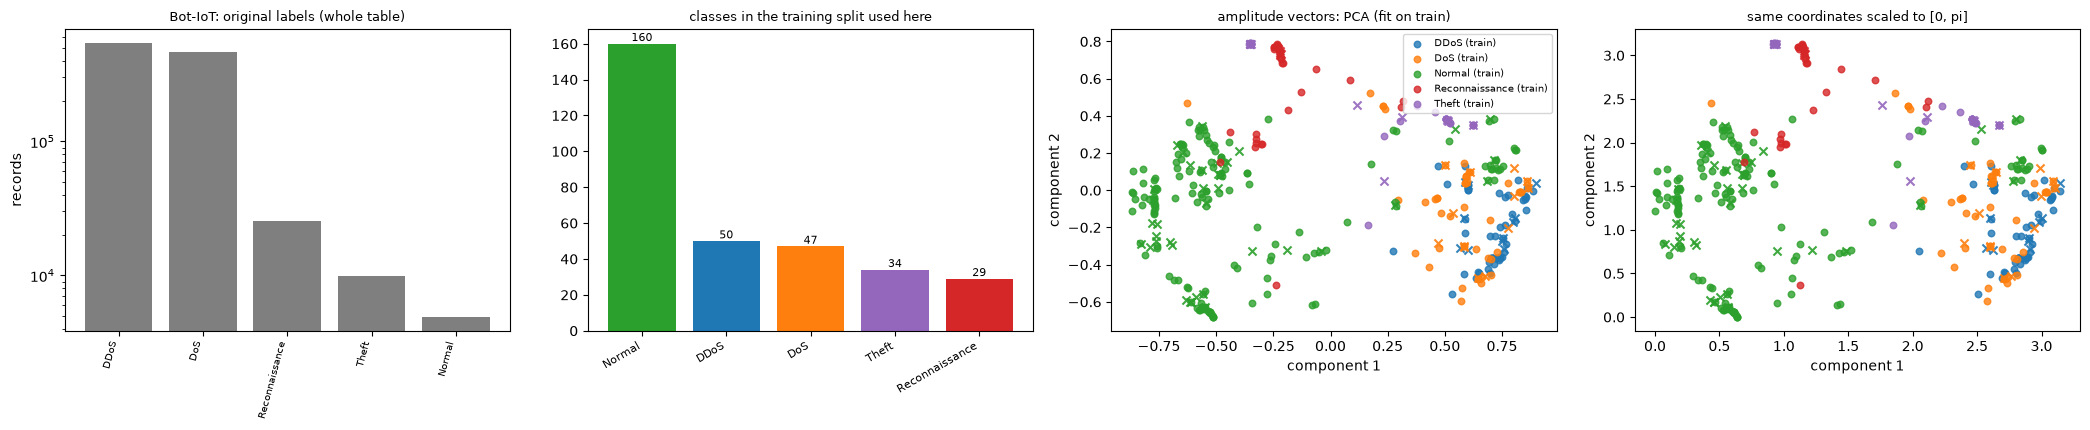

PCA explained variance of the two plotted components: [0.347, 0.148]
IoT-23
original table shape: [819024, 15] | after cleaning / de-duplication: [70707, 12] | cached pool: (60000, 14)
features entering the quantum model (10 of 11, n_q = 4): ['proto', 'service', 'conn_state', 'duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
original label `label`: {'Malicious': 542744, 'Benign': 276280}
sample used: train {'Malicious': np.int64(160), 'Benign': np.int64(160)} | test {'Benign': np.int64(40), 'Malicious': np.int64(40)}


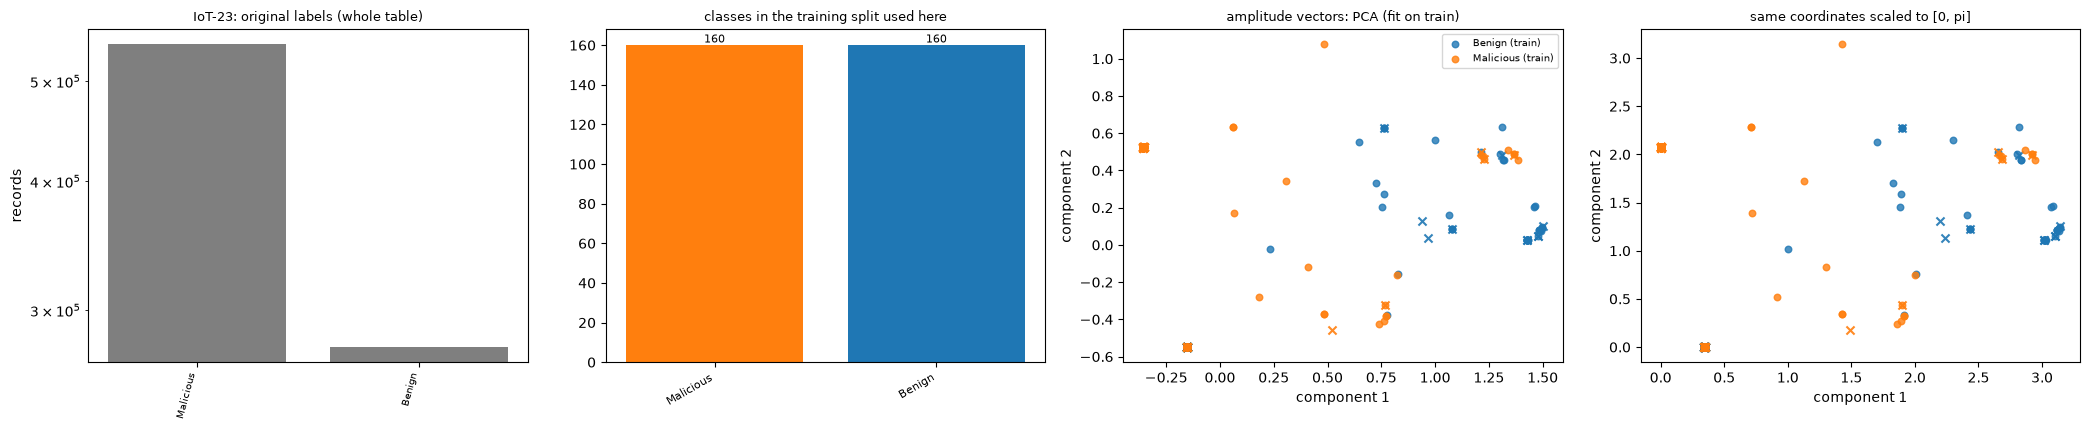

PCA explained variance of the two plotted components: [0.462, 0.395]
KDD99
original table shape: [494021, 42] | after cleaning / de-duplication: [145586, 43] | cached pool: (145586, 45)
features entering the quantum model (32 of 41, n_q = 5): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'hot', 'logged_in', 'num_compromised', 'num_root', 'num_file_creations', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
original label `label` (attack names): {'smurf': 280790, 'neptune': 107201, 'normal': 97278, 'back': 2203, 'satan': 1589, 'ipsweep': 1247, 'portsweep': 1040, 'warezclien

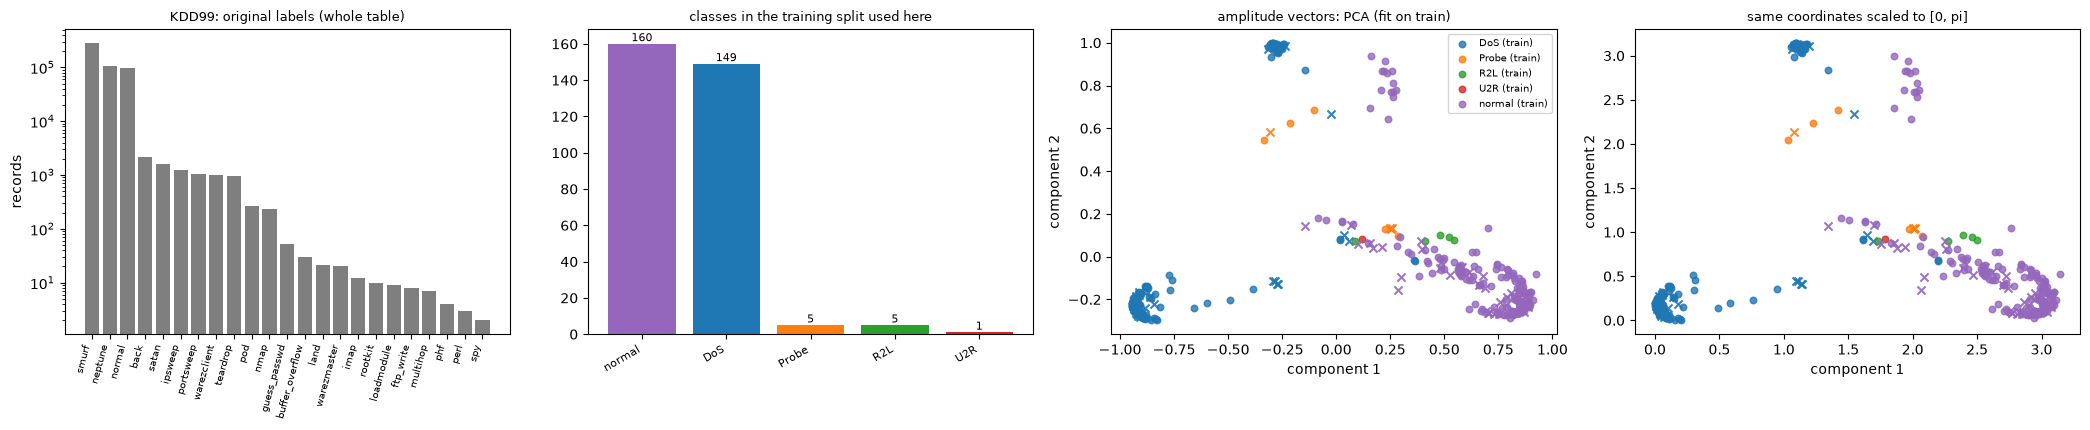

PCA explained variance of the two plotted components: [0.551, 0.167]


In [8]:
def class_colors(labels):
    labs = sorted(set(labels)); cmap = plt.get_cmap("tab10")
    return {l: cmap(i % 10) for i, l in enumerate(labs)}

def explore(ds):
    D, info, pool = get_prepared(ds, SEED), INFO[ds], POOLS[ds]
    print("=" * 110); print(ds)
    print("original table shape:", info["raw_shape"], "| after cleaning / de-duplication:", info.get("clean_shape"), "| cached pool:", pool.shape)
    print(f"features entering the quantum model ({D['d']} of {D['n_raw_features']}, n_q = {D['nq']}):", D["names"])
    if ds == "Bot-IoT":
        orig = pd.Series(info["category"]); print("original label `attack` (0 normal / 1 attack):", info["attack"]); print("original label `category`:", info["category"])
        print("original label `subcategory`:", info["subcategory"])
    elif ds == "IoT-23":
        orig = pd.Series(info["label"]); print("original label `label`:", info["label"])
    else:
        orig = pd.Series(info["label"]); print("original label `label` (attack names):", info["label"]); print("attack families:", info["family"])
    cls_all = np.concatenate([D["cls_tr"], D["cls_te"]]); col = class_colors(list(pool.cls.unique()))
    print("sample used: train", dict(pd.Series(D["cls_tr"]).value_counts()), "| test", dict(pd.Series(D["cls_te"]).value_counts()))
    fig, ax = plt.subplots(1, 4, figsize=(21, 4.4))
    o = orig.sort_values(ascending=False); ax[0].bar(range(len(o)), o.values, color="tab:gray"); ax[0].set_yscale("log")
    ax[0].set_xticks(range(len(o))); ax[0].set_xticklabels(o.index, rotation=75, ha="right", fontsize=7); ax[0].set_title(f"{ds}: original labels (whole table)", fontsize=9); ax[0].set_ylabel("records")
    s = pd.Series(D["cls_tr"]).value_counts()
    ax[1].bar(range(len(s)), s.values, color=[col[k] for k in s.index]); ax[1].set_xticks(range(len(s))); ax[1].set_xticklabels(s.index, rotation=30, ha="right", fontsize=8)
    for i, v in enumerate(s.values): ax[1].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
    ax[1].set_title("classes in the training split used here", fontsize=9)
    pca = PCA(n_components=2, random_state=SEED).fit(D["Xtr"]); Ptr, Pte = pca.transform(D["Xtr"]), pca.transform(D["Xte"])
    sc = MinMaxScaler((0, np.pi)).fit(Ptr); Str, Ste = sc.transform(Ptr), np.clip(sc.transform(Pte), 0, np.pi)
    for a, (A, B, ttl) in zip(ax[2:], [(Ptr, Pte, "amplitude vectors: PCA (fit on train)"), (Str, Ste, "same coordinates scaled to [0, pi]")]):
        for lab in sorted(set(cls_all)):
            m1, m2 = D["cls_tr"] == lab, D["cls_te"] == lab
            a.scatter(A[m1, 0], A[m1, 1], s=22, color=col[lab], alpha=0.8, label=f"{lab} (train)")
            a.scatter(B[m2, 0], B[m2, 1], s=34, color=col[lab], marker="x", alpha=0.9)
        a.set_title(ttl, fontsize=9); a.set_xlabel("component 1"); a.set_ylabel("component 2")
    ax[2].legend(fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    print(f"PCA explained variance of the two plotted components: {pca.explained_variance_ratio_.round(3).tolist()}")

for ds in DATASETS:
    explore(ds)

## Quantum Circuit Architecture

Below are the circuits that the notebook actually executes. They are built by the same code that trains the models (no
illustrative drawings). Everything the paper omits is listed in the table at the top: $n_l=2$, `reps=4`, `RealAmplitudes` with
linear CNOT chain and without the final rotation layer, the kernel feature map and the noise strengths.

**Quantum autoencoder** (one drawing per distinct number of data qubits $n_q$; Bot-IoT and KDD99 use $n_q=5$, IoT-23 has only
11 usable features and uses $n_q=4$). The block `RawFeatureVector` loads the record (its 32 or 16 amplitudes are the circuit
parameters, bound per record), then the `RealAmplitudes` encoder, the SWAP test and the measurement of the auxiliary qubit.
For a second view the encoder and SWAP test are transpiled to the gate set used for the noisy simulation (RY, RZ, SX, X, H, CX).

**Trainable kernel**: the feature map $\Phi(z,\phi)$ and the compute-uncompute circuit $\Phi^\dagger(z_j,\phi)\Phi(z_i,\phi)$ whose
all-zero probability is the kernel entry.

After the drawings, five assertions confirm that the fast formulas used for training are exactly the drawn circuits.

QAE with n_q = 4 data qubits (used by ['IoT-23']): n_l = 2 latent, n_t = 2 trash A + 2 trash B, 1 auxiliary -> 7 qubits


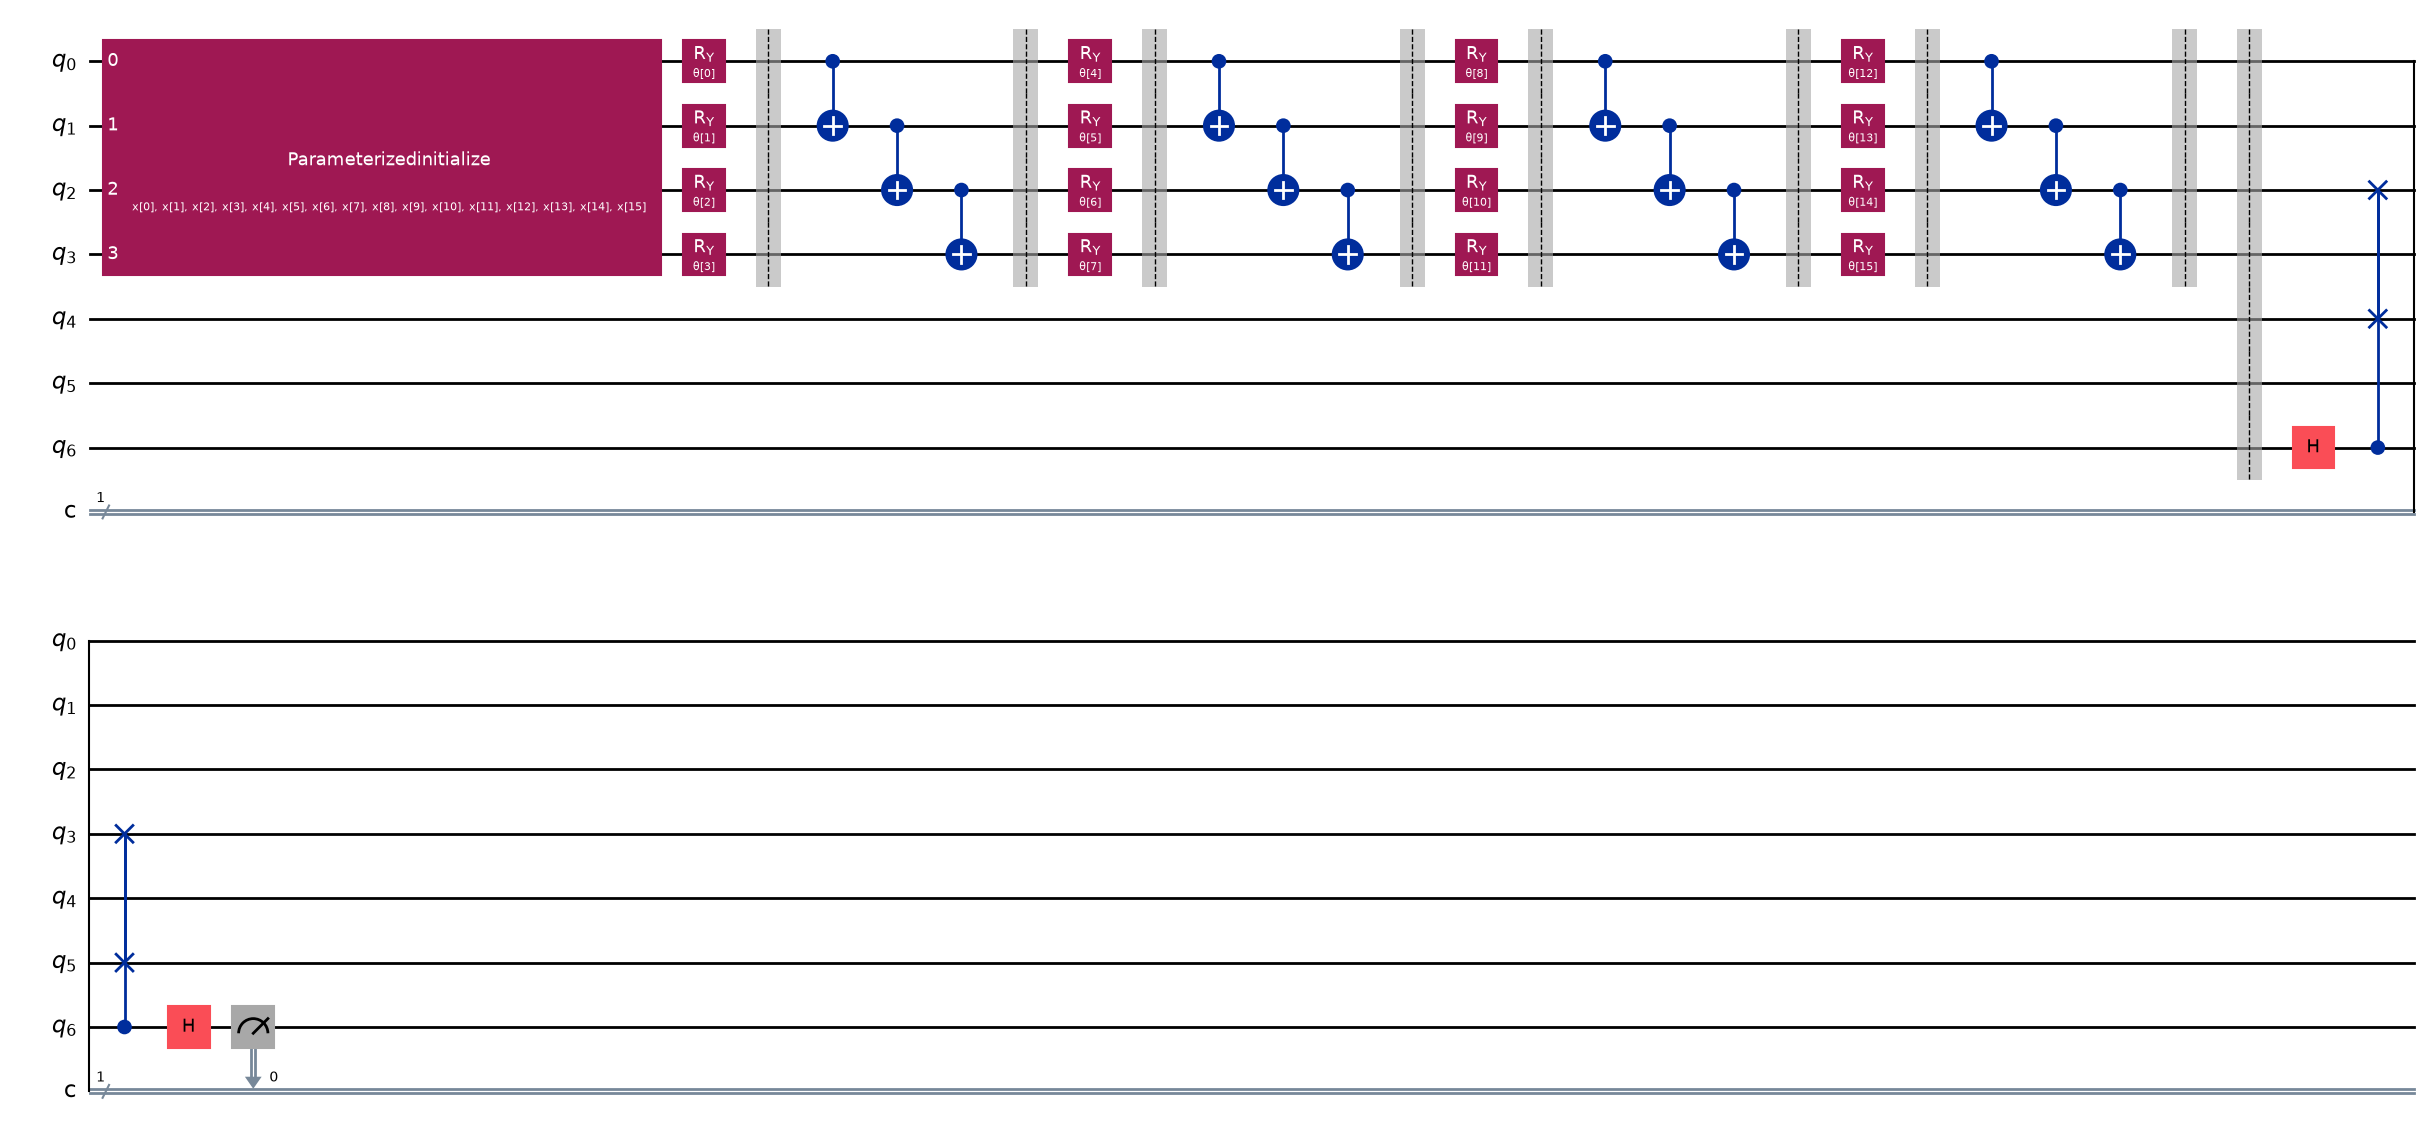

  qubits 7 | trainable encoder parameters 16 (= reps x n_q = 4 x 4) | data parameters (amplitudes) 16
  depth of the encoder + SWAP test transpiled to ['ry', 'rz', 'sx', 'x', 'h', 'cx']: 37 | gate counts {'cx': 28, 'ry': 16, 'rz': 14, 'barrier': 9, 'h': 6}
  amplitude-encoding block RawFeatureVector(16): one state-preparation instruction on 4 qubits (exact; not decomposed into noisy gates)


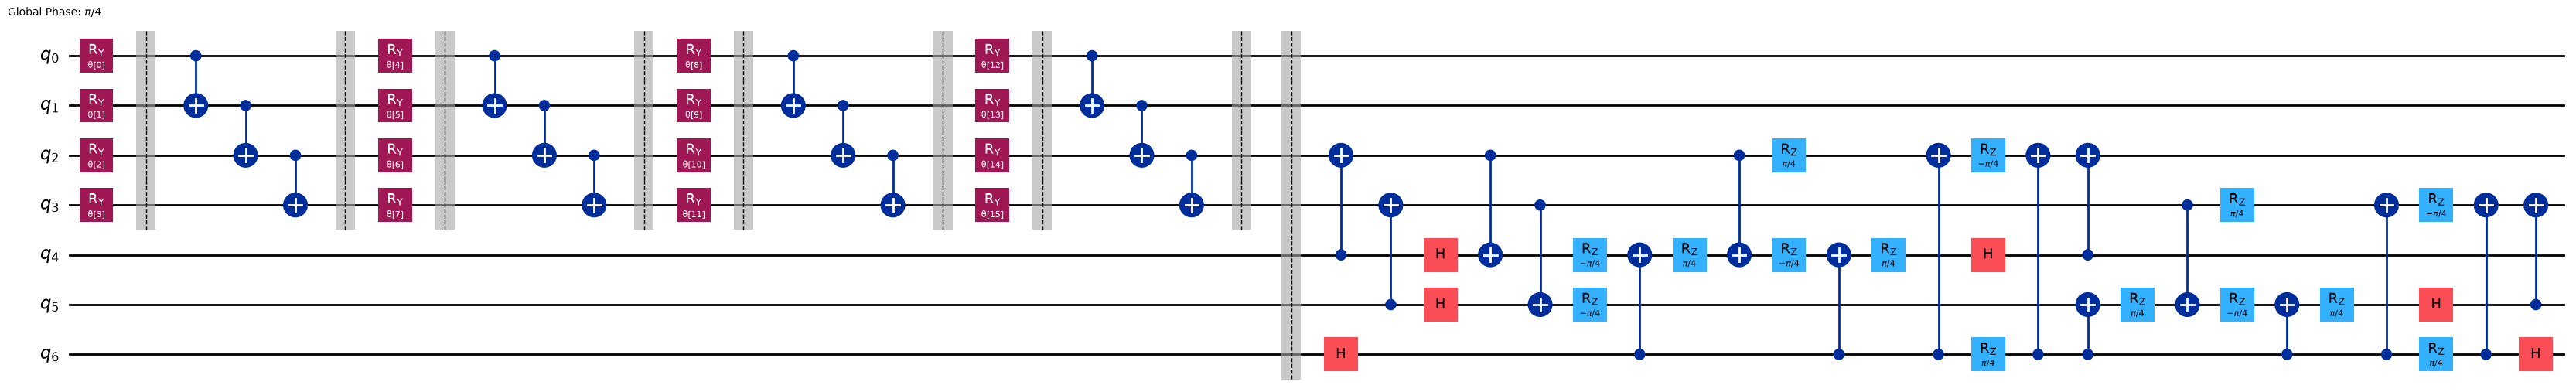

QAE with n_q = 5 data qubits (used by ['Bot-IoT', 'KDD99']): n_l = 2 latent, n_t = 3 trash A + 3 trash B, 1 auxiliary -> 9 qubits


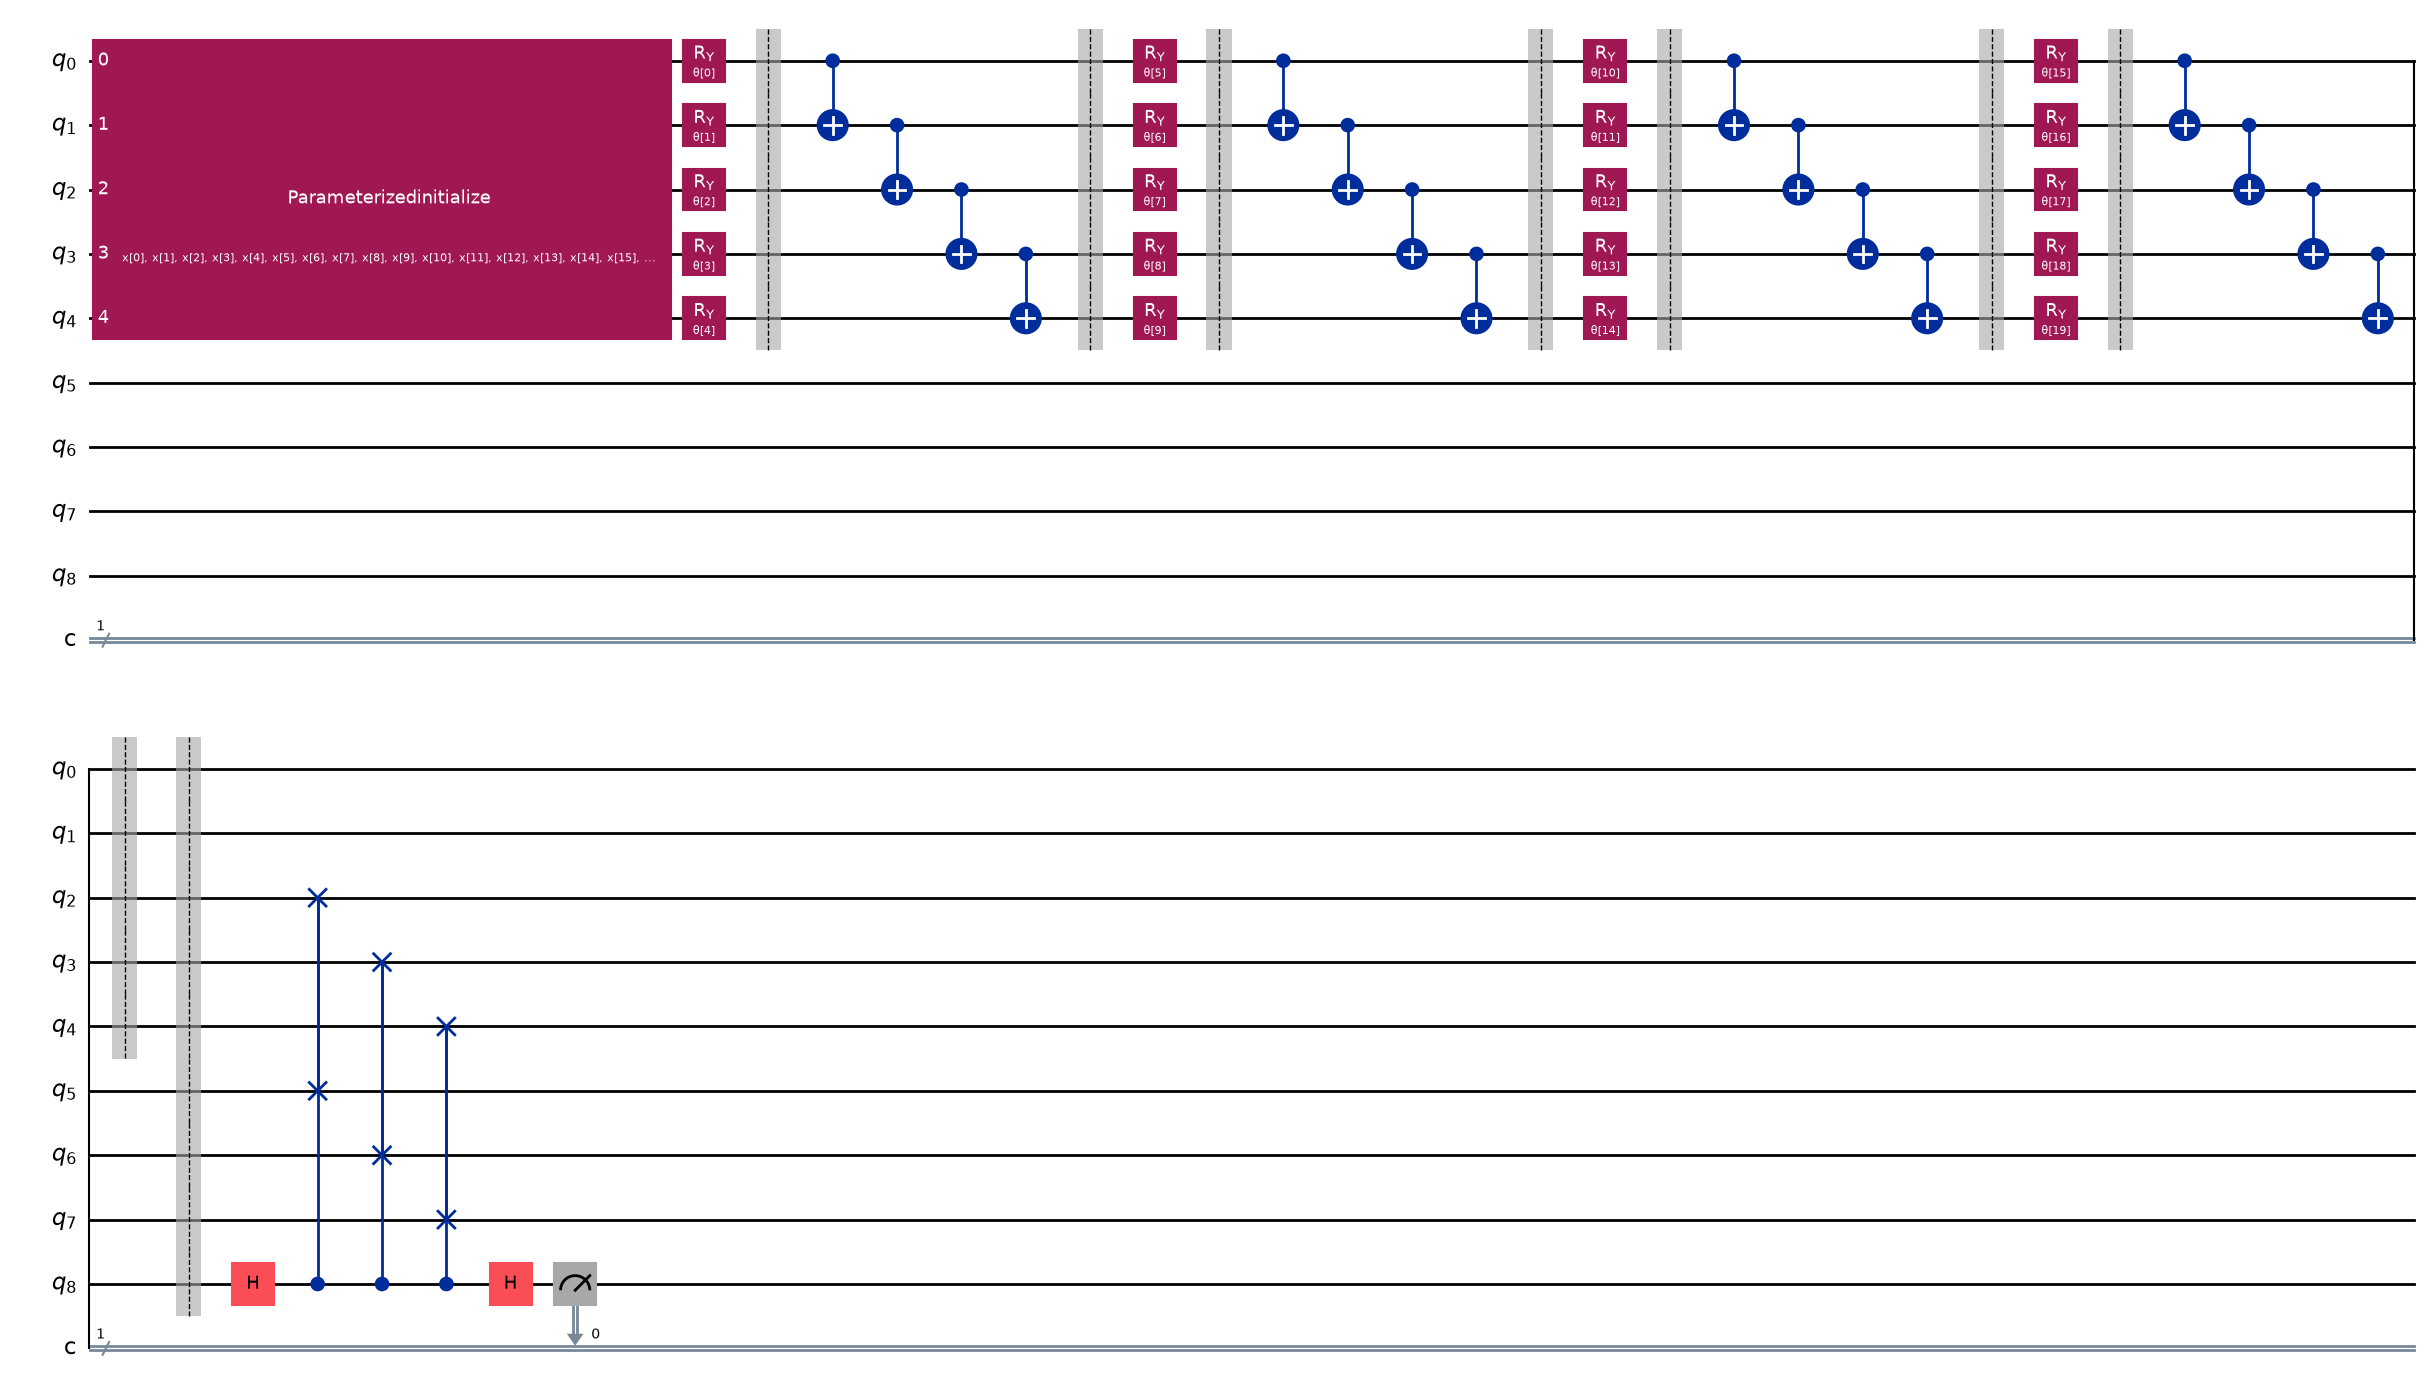

  qubits 9 | trainable encoder parameters 20 (= reps x n_q = 4 x 5) | data parameters (amplitudes) 32
  depth of the encoder + SWAP test transpiled to ['ry', 'rz', 'sx', 'x', 'h', 'cx']: 49 | gate counts {'cx': 40, 'rz': 21, 'ry': 20, 'barrier': 9, 'h': 8}
  amplitude-encoding block RawFeatureVector(32): one state-preparation instruction on 5 qubits (exact; not decomposed into noisy gates)


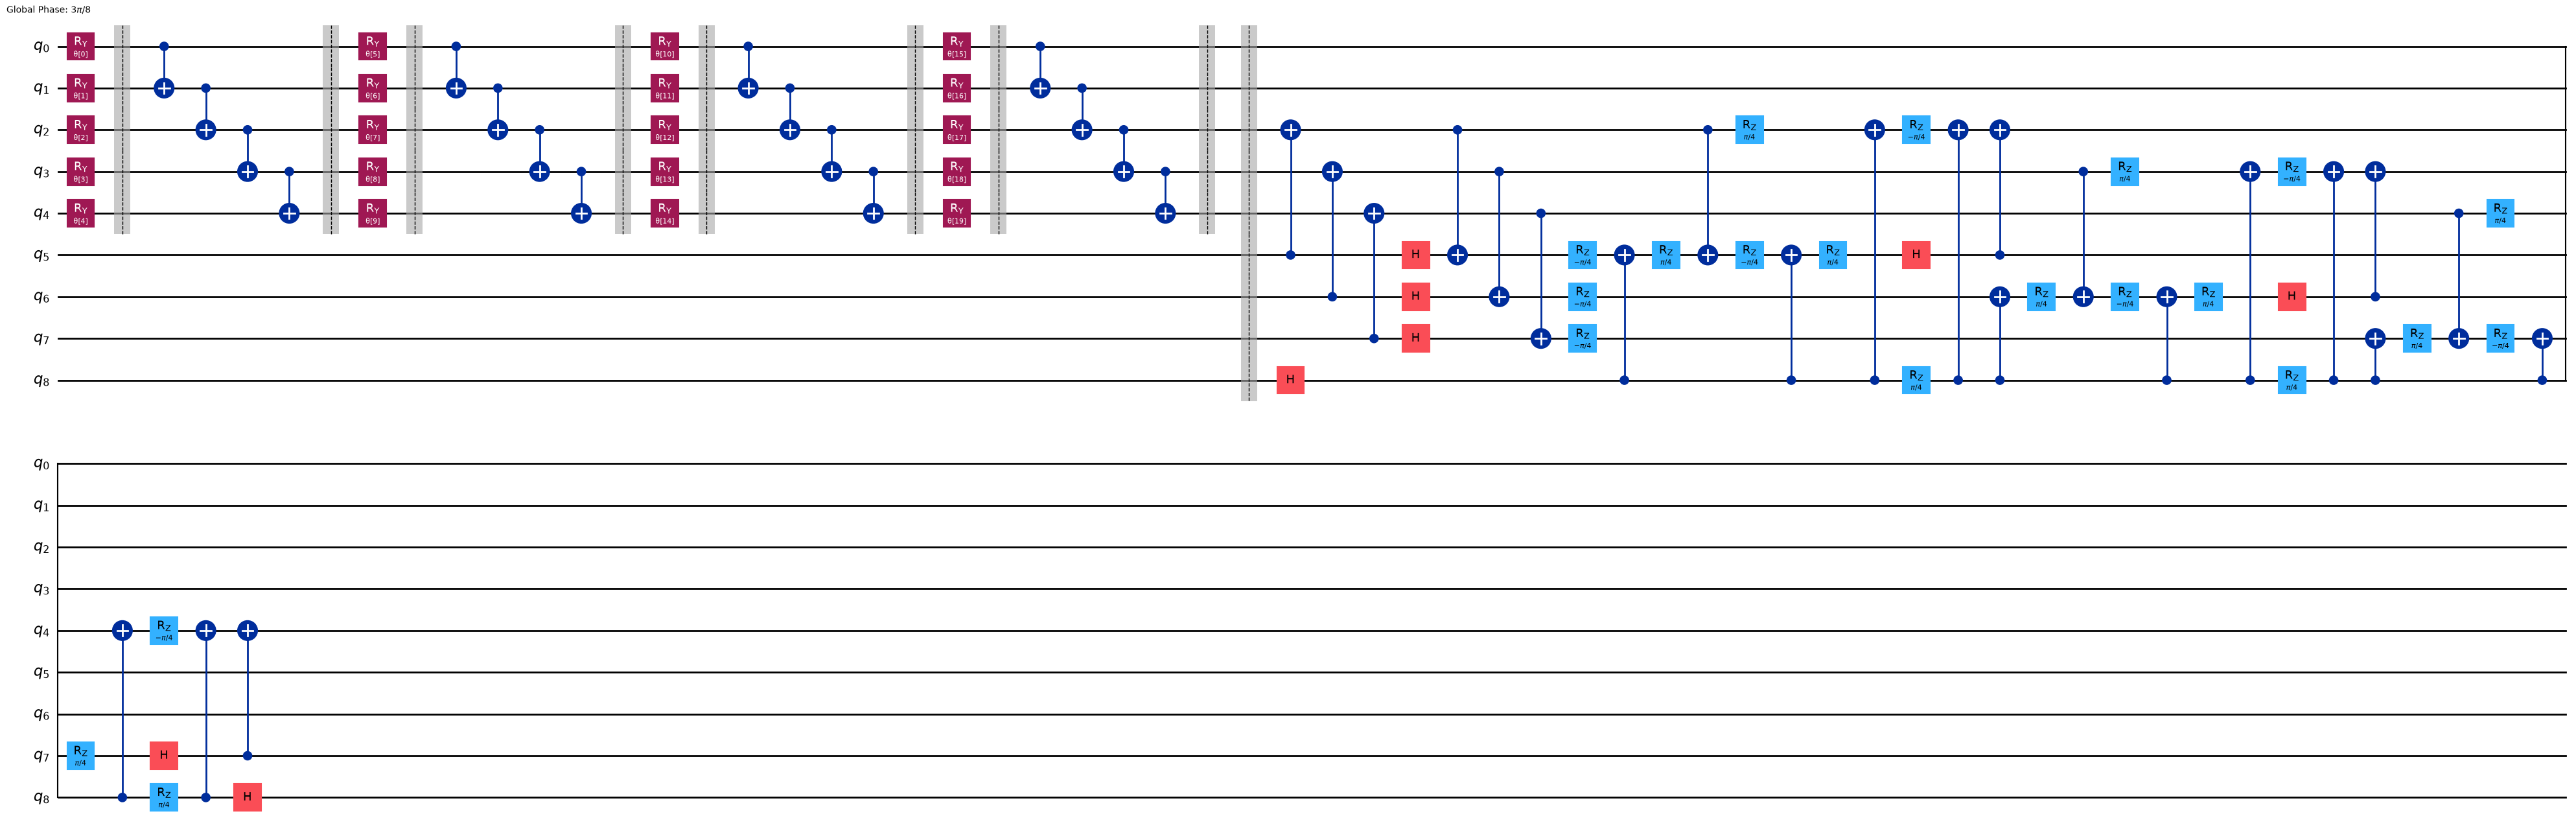

Trainable kernel feature map Phi(z, phi) on 4 qubits


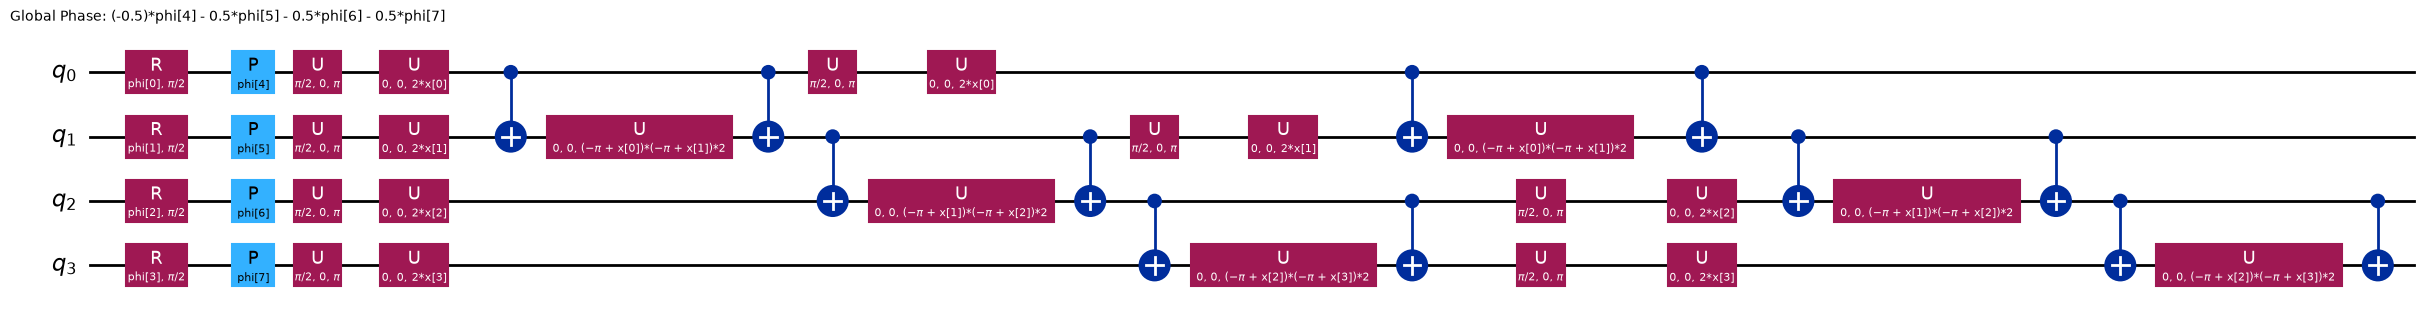

  qubits 4 | trainable parameters 8 | data parameters 4 | depth of the decomposed map 21
Compute-uncompute circuit Phi^dagger(z_j) Phi(z_i) (kernel entry = probability of the all-zero outcome):


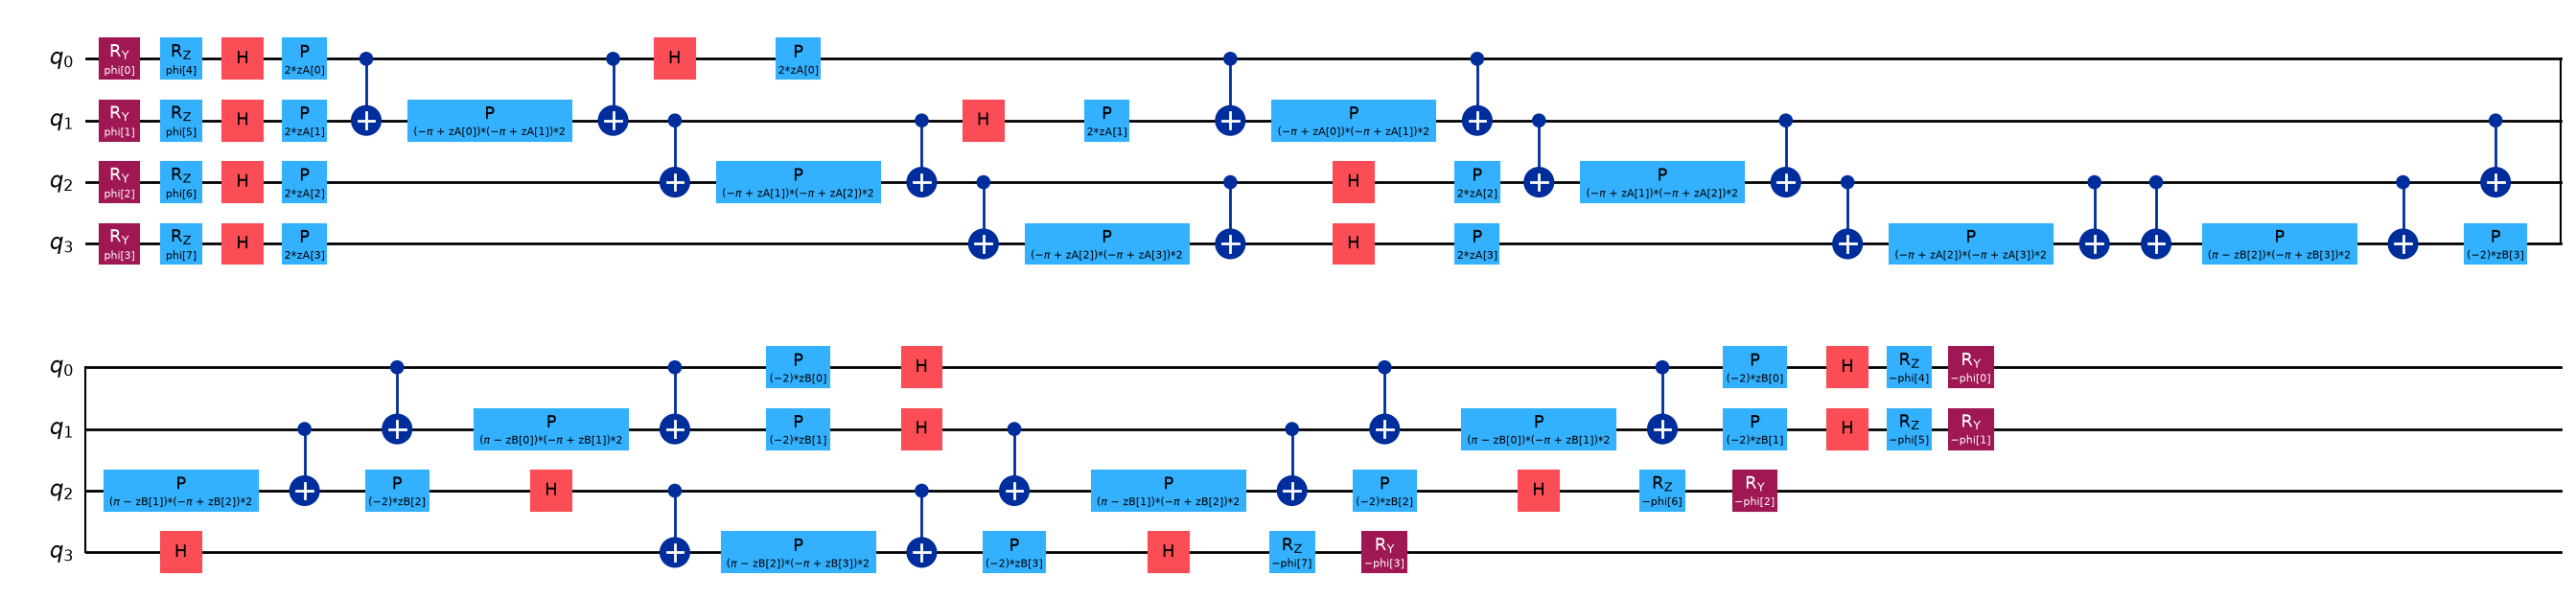

  qubits 4 | depth 42 | gate counts {'rz': 36, 'cx': 24, 'h': 16, 'ry': 8} | trainable parameters 8


In [9]:
def show(circ, **kw):
    fig = circ.draw("mpl", **kw); display(fig); plt.close(fig)

for nq in sorted({get_prepared(ds, SEED)["nq"] for ds in DATASETS}):
    q = get_qae(nq)
    users = [ds for ds in DATASETS if get_prepared(ds, SEED)["nq"] == nq]
    print("=" * 100)
    print(f"QAE with n_q = {nq} data qubits (used by {users}): n_l = {q.nl} latent, n_t = {q.nt} trash A + {q.nt} trash B, 1 auxiliary -> {q.n} qubits")
    show(q.full, fold=36)
    ae_t = transpile(q.core, basis_gates=BASIS, optimization_level=0)
    print(f"  qubits {q.n} | trainable encoder parameters {q.n_params} (= reps x n_q = {ENC_REPS} x {nq}) | data parameters (amplitudes) {2 ** nq}")
    print(f"  depth of the encoder + SWAP test transpiled to {BASIS}: {ae_t.depth()} | gate counts {dict(ae_t.count_ops())}")
    print(f"  amplitude-encoding block RawFeatureVector({2 ** nq}): one state-preparation instruction on {nq} qubits (exact; not decomposed into noisy gates)")
    show(ae_t, fold=60, idle_wires=False)

print("=" * 100); print("Trainable kernel feature map Phi(z, phi) on", KFM.nk, "qubits")
show(KFM.fm.decompose(), fold=40)
print(f"  qubits {KFM.fm.num_qubits} | trainable parameters {len(KFM.phi)} | data parameters {len(KFM.zpar)} | depth of the decomposed map {KFM.fm.decompose().decompose().depth()}")
print("Compute-uncompute circuit Phi^dagger(z_j) Phi(z_i) (kernel entry = probability of the all-zero outcome):")
show(KFM.cu, fold=40)
cu_t = transpile(KFM.cu, basis_gates=BASIS, optimization_level=0)
print(f"  qubits {KFM.cu.num_qubits} | depth {cu_t.depth()} | gate counts {dict(cu_t.count_ops())} | trainable parameters {len(KFM.phi)}")

In [10]:
# ---- equivalence assertions: the fast formulas used for training equal the drawn circuits ----
r = np.random.default_rng(0)
for nq in sorted({get_prepared(ds, SEED)["nq"] for ds in DATASETS}):
    q = get_qae(nq); theta = r.uniform(0, 2 * np.pi, q.n_params)
    X = r.normal(size=(5, 2 ** nq)); X /= np.linalg.norm(X, axis=1, keepdims=True)
    p1_sv, lat_sv = [], []
    for x in X:
        c = QuantumCircuit(q.n); c.compose(q.fm.assign_parameters(x), range(nq), inplace=True); c.compose(q.core.assign_parameters(theta), inplace=True)
        sv = Statevector(c); p1_sv.append(sv.probabilities([q.aux])[1]); lat_sv.append(sv.probabilities(list(range(q.nl))))
    assert np.allclose(p1_sv, q.p_aux1(theta, X), atol=1e-10), "SWAP-test probability: NumPy formula differs from the Qiskit circuit"
    assert np.allclose(lat_sv, q.latent(theta, X), atol=1e-10), "latent distribution: NumPy formula differs from the Qiskit circuit"
    ideal = AerQAE(q, NoiseModel())                                               # Aer density-matrix simulator, no noise
    assert np.allclose(ideal.p_aux1(theta, X), q.p_aux1(theta, X), atol=1e-8), "Aer circuit differs from the NumPy formula"
    assert np.allclose(ideal.latent(theta, X), q.latent(theta, X), atol=1e-8)
    aer_noisy, fast_noisy = AerQAE(q, make_noise_model()), get_noisy_qae(nq)       # depolarizing noise: Aer reference versus the exact fast simulator
    assert np.allclose(aer_noisy.p_aux1(theta, X), fast_noisy.p_aux1(theta, X), atol=1e-9), "fast noisy QAE differs from Aer"
    assert np.allclose(aer_noisy.latent(theta, X), fast_noisy.latent(theta, X), atol=1e-9)
    noisy_p = fast_noisy.p_aux1(theta, X)
    print(f"n_q = {nq}: SWAP-test probability  circuit = formula = Aer(no noise)  [max |diff| {np.abs(np.array(p1_sv) - q.p_aux1(theta, X)).max():.1e}];"
          f" Aer(noise) = fast noisy simulator [max |diff| {np.abs(aer_noisy.p_aux1(theta, X) - noisy_p).max():.1e}]")
    print(f"        same inputs: ideal {np.round(q.p_aux1(theta, X), 3).tolist()} | depolarizing noise {np.round(noisy_p, 3).tolist()}")

ph = r.uniform(0, np.pi, 2 * NK); Z = r.uniform(0, np.pi, (5, NK))
K_fast = FastKernel(KFM); K_fast.assign_training_parameters(ph)
K_qiskit = TrainableFidelityStatevectorKernel(feature_map=KFM.fm, training_parameters=list(KFM.phi)); K_qiskit.assign_training_parameters(ph)
assert np.allclose(K_fast.evaluate(Z), K_qiskit.evaluate(Z), atol=1e-10), "fast kernel differs from Qiskit's trainable statevector kernel"
K_ideal_aer = AerKernel(KFM, NoiseModel()); K_ideal_aer.assign_training_parameters(ph)
assert np.allclose(K_ideal_aer.evaluate(Z[:3], Z), K_fast.evaluate(Z[:3], Z), atol=1e-8), "Aer compute-uncompute circuit differs from the statevector kernel"
K_noisy = AerKernel(KFM, make_noise_model()); K_noisy.assign_training_parameters(ph)
K_noisy_fast = FastNoisyKernel(KFM, P1_ERR, P2_ERR); K_noisy_fast.assign_training_parameters(ph)
assert np.allclose(K_noisy.evaluate(Z[:3], Z), K_noisy_fast.evaluate(Z[:3], Z), atol=1e-9), "fast noisy kernel differs from Aer (test vs train)"
assert np.allclose(K_noisy.evaluate(Z), K_noisy_fast.evaluate(Z), atol=1e-9), "fast noisy kernel differs from Aer (symmetric)"
print("kernel: fast NumPy = Qiskit TrainableFidelityStatevectorKernel = Aer compute-uncompute circuit (no noise); exact Gram matrix:")
print(np.round(K_fast.evaluate(Z), 3))
print("same Gram matrix with depolarizing noise (Aer = fast noisy simulator to 1e-9; entries move towards the noise floor):")
print(np.round(K_noisy_fast.evaluate(Z), 3))

n_q = 4: SWAP-test probability  circuit = formula = Aer(no noise)  [max |diff| 3.9e-16]; Aer(noise) = fast noisy simulator [max |diff| 5.0e-16]
        same inputs: ideal [0.486, 0.217, 0.433, 0.467, 0.392] | depolarizing noise [0.473, 0.262, 0.432, 0.459, 0.4]


n_q = 5: SWAP-test probability  circuit = formula = Aer(no noise)  [max |diff| 1.7e-16]; Aer(noise) = fast noisy simulator [max |diff| 1.2e-15]
        same inputs: ideal [0.398, 0.421, 0.395, 0.384, 0.485] | depolarizing noise [0.417, 0.432, 0.415, 0.409, 0.481]


kernel: fast NumPy = Qiskit TrainableFidelityStatevectorKernel = Aer compute-uncompute circuit (no noise); exact Gram matrix:
[[1.    0.051 0.012 0.134 0.094]
 [0.051 1.    0.017 0.047 0.2  ]
 [0.012 0.017 1.    0.098 0.237]
 [0.134 0.047 0.098 1.    0.361]
 [0.094 0.2   0.237 0.361 1.   ]]
same Gram matrix with depolarizing noise (Aer = fast noisy simulator to 1e-9; entries move towards the noise floor):


[[1.    0.064 0.025 0.127 0.101]
 [0.064 1.    0.022 0.049 0.18 ]
 [0.025 0.022 1.    0.089 0.206]
 [0.127 0.049 0.089 1.    0.305]
 [0.101 0.18  0.206 0.305 1.   ]]


## 4. The whole pipeline as one function

`run_pipeline(dataset, seed, noisy)` does what the paper's Fig. 1 does, in four steps:

1. **Train the quantum autoencoder** with COBYLA. At every optimiser evaluation $B$ random mini-batches of $b$ training records are
   drawn; the evaluation returns the mean of the $B$ batch losses and the notebook logs their standard deviation $\sigma$ and the
   95 % band $\mu\pm1.96\sigma$ (the paper's loss-uncertainty bookkeeping). The *noisy* runs use exactly the same budgets and
   batches; only the circuit simulation changes (depolarizing noise, exact probabilities, i.e. infinitely many shots).
2. **Extract the latent features**: run the trained encoder and read the probability distribution of the $n_l$ latent qubits
   (4 numbers per record), then scale each to $[0,\pi]$ with the training minimum / maximum.
3. **Train the quantum kernel**: `QuantumKernelTrainer` with `SPSA` and the SVC dual loss on a stratified subset of the training
   split; the kernel parameters $\phi$ are the 8 rotation angles of the trainable layer.
4. **Classify with the QSVC**: the full Gram matrix of the trained kernel is computed, $C$ is chosen on a validation split of the
   training data only, and the SVM is fitted on the whole training split. Metrics are the paper's: accuracy and *weighted*
   precision, recall, F1.

A random forest and an RBF-SVM are trained on exactly the same two inputs (the padded amplitude vectors that go into the QAE, and
the latent features that go into the kernel).

In [11]:
def metrics_dict(y, pred):
    kw = dict(zero_division=0)
    return dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, average="weighted", **kw), rec=recall_score(y, pred, average="weighted", **kw),
                f1=f1_score(y, pred, average="weighted", **kw), att_prec=precision_score(y, pred, pos_label=1, **kw),
                att_rec=recall_score(y, pred, pos_label=1, **kw), att_f1=f1_score(y, pred, pos_label=1, **kw))

def grad_norm(p_fun, n_params, theta, X):
    """Norm of the exact gradient of the mean loss by the parameter-shift rule (every parameter is an RY angle; also exact with noise between the gates)."""
    g = np.zeros(n_params)
    for k in range(n_params):
        e = np.zeros(n_params); e[k] = np.pi / 2
        g[k] = 0.5 * (p_fun(theta + e, X).mean() - p_fun(theta - e, X).mean())
    return float(np.linalg.norm(g))

def train_qae(D, seed, noisy, with_grad=False):
    q = get_qae(D["nq"]); nz = get_noisy_qae(D["nq"]) if noisy else None
    B, b, maxiter = QAE_BATCHES, QAE_BATCH, QAE_MAXITER
    X = D["Xtr"]; brng = np.random.default_rng(seed + 1)
    mu, sd, thetas = [], [], []
    def fun(theta):
        idx = np.array([brng.choice(len(X), min(b, len(X)), replace=False) for _ in range(B)])        # B random mini-batches
        p = (nz.p_aux1(theta, X[idx.ravel()]) if noisy else q.p_aux1(theta, X[idx.ravel()])).reshape(B, -1)
        lb = p.mean(axis=1)                                                                           # loss of every batch
        mu.append(float(lb.mean())); sd.append(float(lb.std(ddof=1))); thetas.append(theta.copy())
        return mu[-1]
    theta0 = np.random.default_rng(seed).uniform(0, 2 * np.pi, q.n_params)                          # same start for the ideal and the noisy run
    t0 = time.time(); res = COBYLA(maxiter=maxiter).minimize(fun, theta0); t_qae = time.time() - t0
    theta = np.asarray(res.x, float)
    out = dict(theta=theta, theta0=theta0, mu=np.array(mu), sd=np.array(sd), time=t_qae, n_eval=len(mu),
               exact_loss_start=float(q.p_aux1(theta0, X).mean()), exact_loss_end=float(q.p_aux1(theta, X).mean()))
    if with_grad:                                                                                    # exact gradient norm along the optimisation path
        ks = np.unique(np.linspace(0, len(thetas) - 1, 12).astype(int)); Xg = X[:min(64, len(X))]
        pfun = nz.p_aux1 if noisy else q.p_aux1
        out["grad_it"] = ks; out["grad"] = np.array([grad_norm(pfun, q.n_params, thetas[k], Xg) for k in ks])
    return out

def kernel_stage(Ztr, ytr, Zte, yte, seed, noisy, trained=True, check_qsvc=False):
    sc = MinMaxScaler((0, np.pi)).fit(Ztr); Atr, Ate = sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi)
    kern = FastNoisyKernel(KFM, P1_ERR, P2_ERR) if noisy else FastKernel(KFM)
    M, iters = KERNEL_M, SPSA_ITERS
    init = np.random.default_rng(seed + 2).uniform(0, np.pi, 2 * NK)
    sub = train_test_split(np.arange(len(ytr)), train_size=min(M, len(ytr) - 2), stratify=ytr, random_state=seed)[0]
    hist, t0 = [], time.time()
    if trained:
        tr = QuantumKernelTrainer(quantum_kernel=kern, loss=SVCLoss(C=1.0), optimizer=SPSA(maxiter=iters, learning_rate=SPSA_LR, perturbation=SPSA_C,
                                  callback=lambda n, x, f, s, a: hist.append(float(f))), initial_point=init)
        kern = tr.fit(Atr[sub], ytr[sub]).quantum_kernel
    else:
        kern.assign_training_parameters(init)
    t_kernel_train = time.time() - t0; t0 = time.time()
    Ktr, Kte = kern.evaluate(Atr), kern.evaluate(Ate, Atr)                                           # Gram matrices of the (trained) kernel
    itr, iva = train_test_split(np.arange(len(ytr)), test_size=VAL_FRACTION, stratify=ytr, random_state=seed)   # C chosen on the training split only
    val = {C: accuracy_score(ytr[iva], SVC(kernel="precomputed", C=C).fit(Ktr[np.ix_(itr, itr)], ytr[itr]).predict(Ktr[np.ix_(iva, itr)])) for C in C_GRID}
    C_best = max(C_GRID, key=lambda C: (val[C], -C))                                                 # ties -> smaller C
    clf = SVC(kernel="precomputed", C=C_best).fit(Ktr, ytr)
    p_tr, p_te = clf.predict(Ktr), clf.predict(Kte); t_fit = time.time() - t0
    out = dict(C=C_best, val=val, phi=np.asarray(kern.parameter_values, float), phi0=init, spsa_loss=np.array(hist), Atr=Atr, Ate=Ate, Ktr=Ktr, Kte=Kte,
               pred_tr=p_tr, pred_te=p_te, m_tr=metrics_dict(ytr, p_tr), m_te=metrics_dict(yte, p_te), t_kernel_train=t_kernel_train, t_fit=t_fit,
               n_sims=getattr(kern, "n_sims", 0))
    if check_qsvc and not noisy:                                                                     # Qiskit's own QSVC gives the same decisions
        qs = QSVC(quantum_kernel=kern, C=C_best).fit(Atr, ytr)
        out["qsvc_identical"] = bool(np.array_equal(qs.predict(Ate), p_te))
    return out

def classical(Xtr, ytr, Xte, yte, seed):
    res = {}
    for name, mdl in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=seed)), ("SVC (rbf)", SVC(kernel="rbf", C=1.0, gamma="scale"))]:
        t0 = time.time(); mdl.fit(Xtr, ytr); p = mdl.predict(Xte); res[name] = dict(metrics_dict(yte, p), time=time.time() - t0, pred=p)
    return res

def run_pipeline(ds, seed, noisy, with_grad=False, check_qsvc=False):
    D = get_prepared(ds, seed); q = get_qae(D["nq"]); t_all = time.time()
    qa = train_qae(D, seed, noisy, with_grad)
    lat = (get_noisy_qae(D["nq"]) if noisy else q).latent
    t0 = time.time(); Ztr, Zte = lat(qa["theta"], D["Xtr"]), lat(qa["theta"], D["Xte"]); t_lat = time.time() - t0
    ks = kernel_stage(Ztr, D["ytr"], Zte, D["yte"], seed, noisy, check_qsvc=check_qsvc)
    zs = StandardScaler().fit(Ztr)
    return dict(ds=ds, seed=seed, noisy=noisy, D=D, qae=qa, Ztr=Ztr, Zte=Zte, kern=ks, time=time.time() - t_all, t_latent=t_lat,
                base_amp=classical(D["Xtr"], D["ytr"], D["Xte"], D["yte"], seed),
                base_lat=classical(zs.transform(Ztr), D["ytr"], zs.transform(Zte), D["yte"], seed))
print("pipeline defined")

pipeline defined


## 5. Ideal run, then the same run under depolarizing noise (seed 42)

First the ideal pipeline for the three data sets (exact simulation, no noise), then the same data split, the same initial
parameters, the same budgets and the same architecture with depolarizing noise ($p_1$, $p_2$ from the config cell) in the exact
density-matrix simulator. Both runs record the exact gradient norm of the QAE loss along the optimisation path (the paper's Fig. 3
quantity, parameter-shift rule); the ideal run also checks that Qiskit's own `QSVC` with the trained kernel gives the same test
predictions as the precomputed-kernel SVM.

In [12]:
MAIN = {}
for ds in DATASETS:
    t0 = time.time(); R = run_pipeline(ds, SEED, noisy=False, with_grad=True, check_qsvc=True); MAIN[(ds, "ideal")] = R
    qa, ks = R["qae"], R["kern"]
    print(f"[ideal] {ds:8s} QAE loss {qa['exact_loss_start']:.3f} -> {qa['exact_loss_end']:.3f} ({qa['n_eval']} evals, {qa['time']:.0f} s) | "
          f"kernel SPSA loss {ks['spsa_loss'][0]:.2f} -> {ks['spsa_loss'][-1]:.2f}, C = {ks['C']:g} | QSVC train/test acc {ks['m_tr']['acc']:.3f} / {ks['m_te']['acc']:.3f} "
          f"| QSVC==Qiskit QSVC: {ks['qsvc_identical']} | {time.time() - t0:.0f} s")

[ideal] Bot-IoT  QAE loss 0.435 -> 0.368 (158 evals, 17 s) | kernel SPSA loss 26.05 -> 22.45, C = 10 | QSVC train/test acc 0.991 / 0.812 | QSVC==Qiskit QSVC: True | 93 s


[ideal] IoT-23   QAE loss 0.395 -> 0.208 (145 evals, 12 s) | kernel SPSA loss 10.26 -> 9.30, C = 100 | QSVC train/test acc 0.947 / 0.825 | QSVC==Qiskit QSVC: True | 54 s


[ideal] KDD99    QAE loss 0.454 -> 0.312 (172 evals, 15 s) | kernel SPSA loss 21.61 -> 18.23, C = 1 | QSVC train/test acc 0.925 / 0.875 | QSVC==Qiskit QSVC: True | 65 s


In [13]:
for ds in DATASETS:
    t0 = time.time(); R = run_pipeline(ds, SEED, noisy=True, with_grad=True); MAIN[(ds, "noisy")] = R
    qa, ks = R["qae"], R["kern"]
    print(f"[noisy] {ds:8s} QAE batch-loss {qa['mu'][0]:.3f} -> {np.mean(qa['mu'][-5:]):.3f} ({qa['n_eval']} evals, {qa['time']:.0f} s; ideal loss of the learned theta {qa['exact_loss_end']:.3f}) | "
          f"noisy-kernel simulations {ks['n_sims']:,} | SPSA loss {ks['spsa_loss'][0]:.2f} -> {ks['spsa_loss'][-1]:.2f}, C = {ks['C']:g} | QSVC train/test acc "
          f"{ks['m_tr']['acc']:.3f} / {ks['m_te']['acc']:.3f} | {time.time() - t0:.0f} s")

[noisy] Bot-IoT  QAE batch-loss 0.441 -> 0.395 (158 evals, 12 s; ideal loss of the learned theta 0.368) | noisy-kernel simulations 15,560 | SPSA loss 25.85 -> 21.93, C = 1 | QSVC train/test acc 0.963 / 0.800 | 610 s


[noisy] IoT-23   QAE batch-loss 0.409 -> 0.235 (153 evals, 17 s; ideal loss of the learned theta 0.176) | noisy-kernel simulations 15,560 | SPSA loss 10.47 -> 9.95, C = 1 | QSVC train/test acc 0.938 / 0.875 | 577 s


[noisy] KDD99    QAE batch-loss 0.455 -> 0.355 (174 evals, 63 s; ideal loss of the learned theta 0.312) | noisy-kernel simulations 15,560 | SPSA loss 21.42 -> 18.74, C = 1 | QSVC train/test acc 0.938 / 0.863 | 1102 s


## 6. Results: the notebook's Table II next to the paper's

Metrics follow the paper: accuracy and **weighted** precision / recall / F1 (in the paper's Table II recall equals accuracy, which
is what weighted recall does). Times are wall-clock seconds on this machine and are not comparable with the paper's
(8.4e4 to 1.6e5 s on a much larger simulation). Test sets here are small (see the config cell), so one test record moves the
accuracy by several points: read the verdicts with that granularity in mind.

Notebook (QAE + trained-kernel QSVC):


,dataset,noise,n_train,n_test,train_acc,test_acc,train_prec,test_prec,train_rec,test_rec,train_f1,test_f1,time_s
0,Bot-IoT,none,320,80,0.9906,0.8125,0.9906,0.8292,0.9906,0.8125,0.9906,0.8101,75.8727
1,IoT-23,none,320,80,0.9469,0.8250,0.9508,0.8385,0.9469,0.8250,0.9468,0.8232,38.6209
2,KDD99,none,320,80,0.9250,0.8750,0.9251,0.8759,0.9250,0.8750,0.9250,0.8749,53.2364
3,Bot-IoT,depolarizing,320,80,0.9625,0.8000,0.9625,0.8200,0.9625,0.8000,0.9625,0.7968,579.0369
4,IoT-23,depolarizing,320,80,0.9375,0.8750,0.9400,0.9000,0.9375,0.8750,0.9374,0.8730,534.8002
5,KDD99,depolarizing,320,80,0.9375,0.8625,0.9376,0.8740,0.9375,0.8625,0.9375,0.8614,981.4506


Paper, Table II:


,dataset,noise,train_acc,test_acc,train_prec,test_prec,train_rec,test_rec,train_f1,test_f1,time_s
0,Bot-IoT,depolarizing,0.9734,0.9545,0.9748,0.9581,0.9738,0.9545,0.9734,0.9543,91706.6
1,IoT-23,depolarizing,0.9833,0.9737,0.9973,0.9836,0.9833,0.9833,0.9283,0.9222,86906.5
2,KDD99,depolarizing,0.9875,0.9833,0.9884,0.9847,0.9874,0.9833,0.9876,0.9836,86245.4
3,Bot-IoT,none,0.9962,0.9242,0.9960,0.9247,0.9962,0.9242,0.9961,0.9294,157369.7
4,IoT-23,none,0.9875,0.9950,0.9562,0.9650,0.9875,0.9500,0.9453,0.9268,99167.8
5,KDD99,none,0.9875,0.9766,0.9874,0.9543,0.9875,0.9857,0.9874,0.9766,84069.4


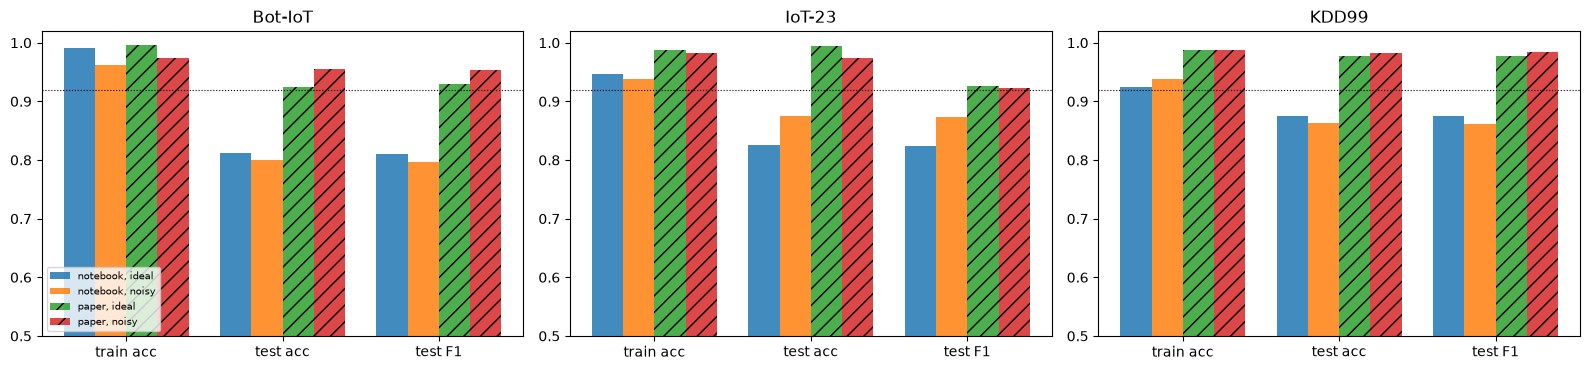

In [14]:
PAPER_T2 = {  # (train acc, test acc, train prec, test prec, train rec, test rec, train f1, test f1, time)
    ("Bot-IoT", "ideal"): (0.9962, 0.9242, 0.9960, 0.9247, 0.9962, 0.9242, 0.9961, 0.9294, 157369.7),
    ("IoT-23",  "ideal"): (0.9875, 0.9950, 0.9562, 0.9650, 0.9875, 0.9500, 0.9453, 0.9268, 99167.8),
    ("KDD99",   "ideal"): (0.9875, 0.9766, 0.9874, 0.9543, 0.9875, 0.9857, 0.9874, 0.9766, 84069.4),
    ("Bot-IoT", "noisy"): (0.9734, 0.9545, 0.9748, 0.9581, 0.9738, 0.9545, 0.9734, 0.9543, 91706.6),
    ("IoT-23",  "noisy"): (0.9833, 0.9737, 0.9973, 0.9836, 0.9833, 0.9833, 0.9283, 0.9222, 86906.5),
    ("KDD99",   "noisy"): (0.9875, 0.9833, 0.9884, 0.9847, 0.9874, 0.9833, 0.9876, 0.9836, 86245.4)}
T2_COLS = ["train_acc", "test_acc", "train_prec", "test_prec", "train_rec", "test_rec", "train_f1", "test_f1", "time_s"]
TOL = 0.02

def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded" if ours > paper else "not reached"

rows = []
for (ds, cond), R in MAIN.items():
    ks = R["kern"]; mt, me = ks["m_tr"], ks["m_te"]
    rows.append(dict(dataset=ds, noise="depolarizing" if cond == "noisy" else "none", n_train=len(R["D"]["ytr"]), n_test=len(R["D"]["yte"]),
                     train_acc=mt["acc"], test_acc=me["acc"], train_prec=mt["prec"], test_prec=me["prec"], train_rec=mt["rec"], test_rec=me["rec"],
                     train_f1=mt["f1"], test_f1=me["f1"], time_s=R["time"]))
T2 = pd.DataFrame(rows)                                                                           # MAIN holds the ideal runs first, then the noisy ones
print("Notebook (QAE + trained-kernel QSVC):"); display(T2.round(4))
paper_rows = [dict(dataset=ds, noise="depolarizing" if c == "noisy" else "none", **dict(zip(T2_COLS, v))) for (ds, c), v in PAPER_T2.items()]
print("Paper, Table II:"); display(pd.DataFrame(paper_rows).sort_values(["noise", "dataset"]).reset_index(drop=True).round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, ds in zip(ax, DATASETS):
    R = MAIN[(ds, "ideal")]; Rn = MAIN[(ds, "noisy")]
    labels = ["train acc", "test acc", "test F1"]
    vals = {"notebook, ideal": [R["kern"]["m_tr"]["acc"], R["kern"]["m_te"]["acc"], R["kern"]["m_te"]["f1"]],
            "notebook, noisy": [Rn["kern"]["m_tr"]["acc"], Rn["kern"]["m_te"]["acc"], Rn["kern"]["m_te"]["f1"]],
            "paper, ideal": [PAPER_T2[(ds, "ideal")][0], PAPER_T2[(ds, "ideal")][1], PAPER_T2[(ds, "ideal")][7]],
            "paper, noisy": [PAPER_T2[(ds, "noisy")][0], PAPER_T2[(ds, "noisy")][1], PAPER_T2[(ds, "noisy")][7]]}
    w = 0.2
    for k, (name, v) in enumerate(vals.items()):
        a.bar(np.arange(3) + (k - 1.5) * w, v, width=w, label=name, hatch="//" if name.startswith("paper") else None, alpha=0.85)
    a.set_xticks(range(3)); a.set_xticklabels(labels); a.set_ylim(0.5, 1.02); a.set_title(ds); a.axhline(0.92, color="k", ls=":", lw=0.8)
ax[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

### Confusion matrices and the learned latent space

Confusion matrices of the QSVC on the **test** records (attack is the positive class), ideal and noisy. Below them, the
**latent features** produced by the trained quantum autoencoder: first the raw latent probabilities (first two of the four), then
the same two angles scaled to $[0,\pi]$, as the trainable kernel receives them. Every point is a real record coloured by its
ground-truth class (circles = training, crosses = test).

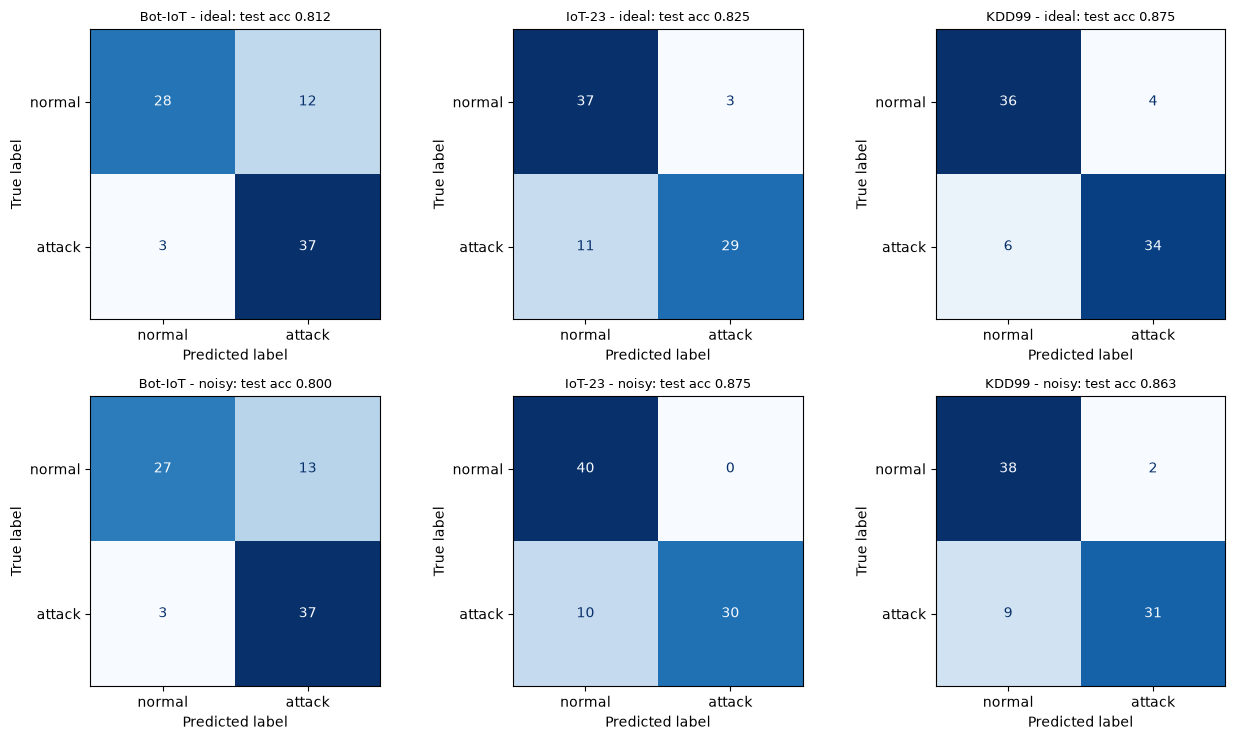

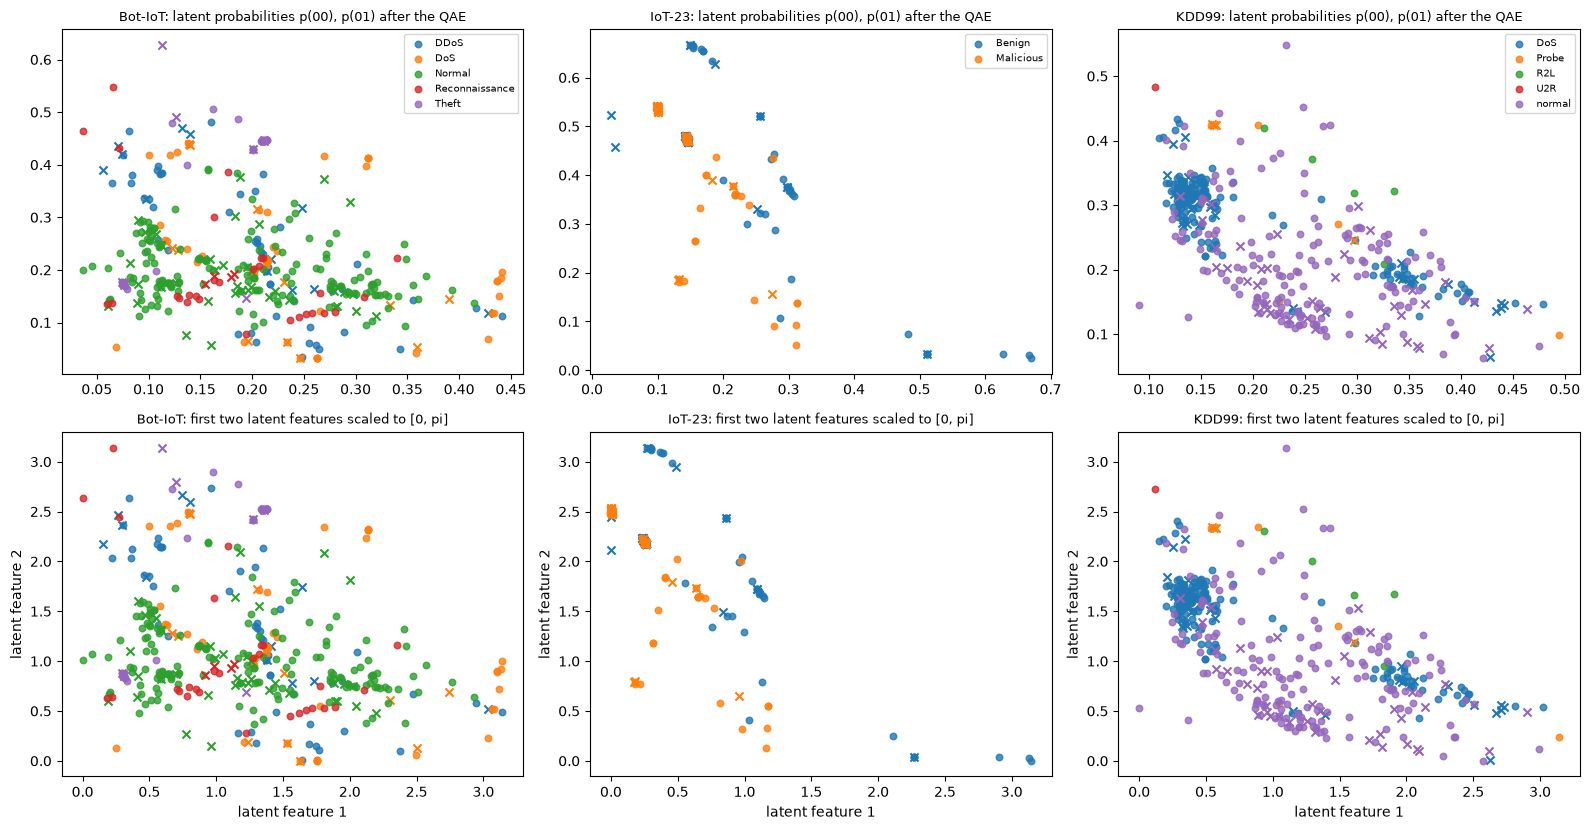

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
for j, ds in enumerate(DATASETS):
    for i, cond in enumerate(["ideal", "noisy"]):
        R = MAIN[(ds, cond)]; cm = confusion_matrix(R["D"]["yte"], R["kern"]["pred_te"], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=ax[i, j], colorbar=False, cmap="Blues")
        ax[i, j].set_title(f"{ds} - {cond}: test acc {R['kern']['m_te']['acc']:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(16, 8.4))
for j, ds in enumerate(DATASETS):
    R = MAIN[(ds, "ideal")]; D = R["D"]; col = class_colors(list(POOLS[ds].cls.unique()))
    for lab in sorted(set(D["cls_tr"]) | set(D["cls_te"])):
        m1, m2 = D["cls_tr"] == lab, D["cls_te"] == lab
        ax[0, j].scatter(R["Ztr"][m1, 0], R["Ztr"][m1, 1], s=22, color=col[lab], alpha=0.8, label=f"{lab}"); ax[0, j].scatter(R["Zte"][m2, 0], R["Zte"][m2, 1], s=34, marker="x", color=col[lab])
        ax[1, j].scatter(R["kern"]["Atr"][m1, 0], R["kern"]["Atr"][m1, 1], s=22, color=col[lab], alpha=0.8); ax[1, j].scatter(R["kern"]["Ate"][m2, 0], R["kern"]["Ate"][m2, 1], s=34, marker="x", color=col[lab])
    ax[0, j].set_title(f"{ds}: latent probabilities p(00), p(01) after the QAE", fontsize=9); ax[0, j].legend(fontsize=7)
    ax[1, j].set_title(f"{ds}: first two latent features scaled to [0, pi]", fontsize=9); ax[1, j].set_xlabel("latent feature 1"); ax[1, j].set_ylabel("latent feature 2")
plt.tight_layout(); plt.show()

### QAE loss statistics (Table I), loss curves (Fig. 2), gradients (Fig. 3) and coefficient of variation (Fig. 4)

For every optimiser evaluation the notebook has the mean loss $\mu$ over the $B$ mini-batches and their standard deviation
$\sigma$. As in the paper, "average loss std" is $\sigma$ averaged over the run and the "lower / upper bound" are the
averages of $\mu-1.96\sigma$ and $\mu+1.96\sigma$. The coefficient of variation is $\sigma/\mu$. The absolute size of $\sigma$ depends on the
(unspecified) batch size, so only the order of magnitude is comparable. Ideal and noisy runs use identical batches and budgets.

,dataset,noise,evals,loss_start,loss_end_mean_last10,avg_loss_std,avg_lower,avg_upper,exact_loss_of_final_theta,paper_std,paper_lower,paper_upper
0,Bot-IoT,ideal,158,0.4308,0.3672,0.0090,0.3561,0.3914,0.3679,0.0191,0.1843,0.2590
1,IoT-23,ideal,145,0.4022,0.2080,0.0099,0.2208,0.2594,0.2081,0.0171,0.2576,0.3244
2,KDD99,ideal,172,0.4496,0.3131,0.0119,0.3079,0.3544,0.3121,0.0213,0.2826,0.3660
3,Bot-IoT,noisy,158,0.4414,0.3963,0.0064,0.3884,0.4135,0.3678,0.0168,0.2906,0.3564
4,IoT-23,noisy,153,0.4087,0.2320,0.0081,0.2492,0.2808,0.1762,0.0302,0.1513,0.2699
5,KDD99,noisy,174,0.4550,0.3567,0.0084,0.3534,0.3865,0.3123,0.0169,0.2644,0.3308


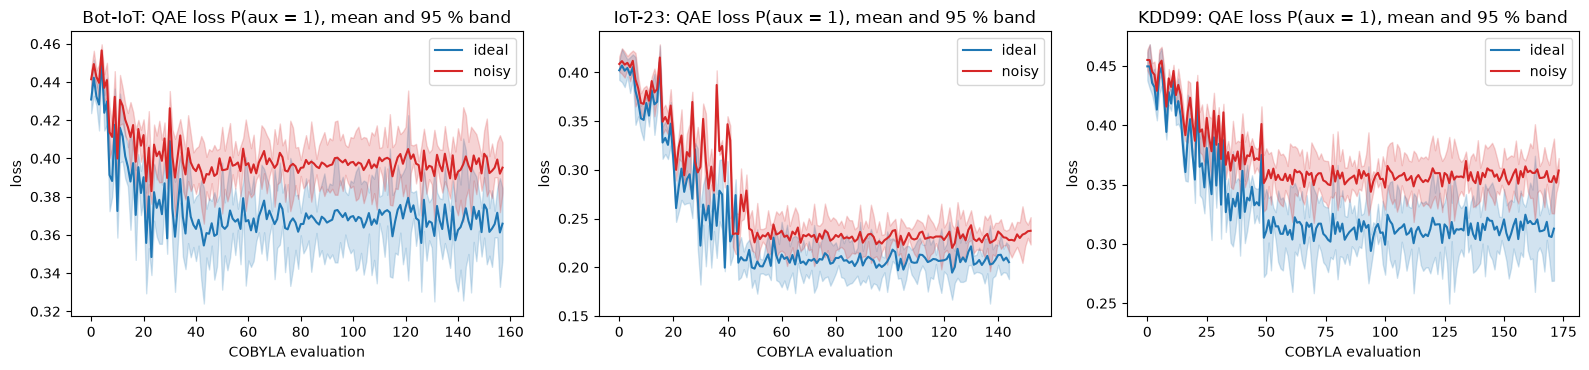

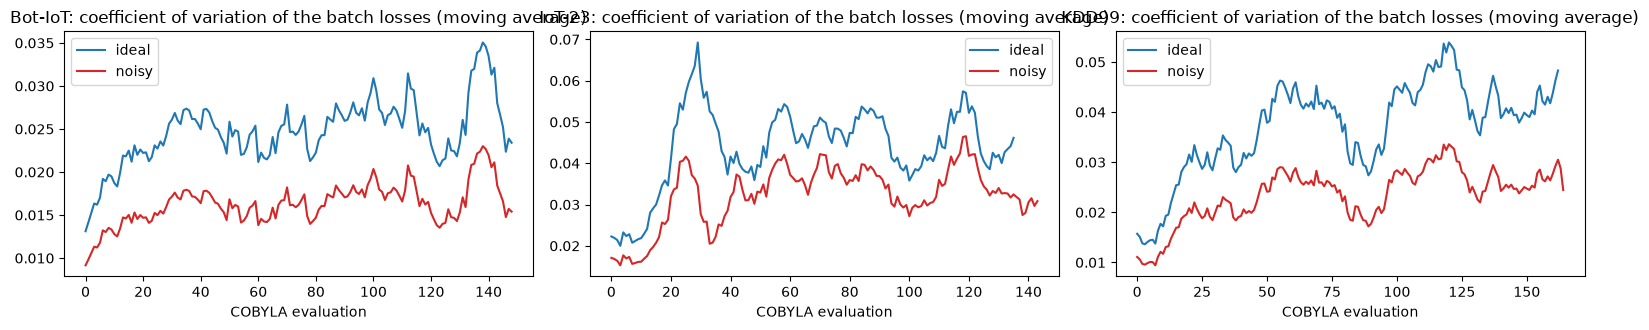

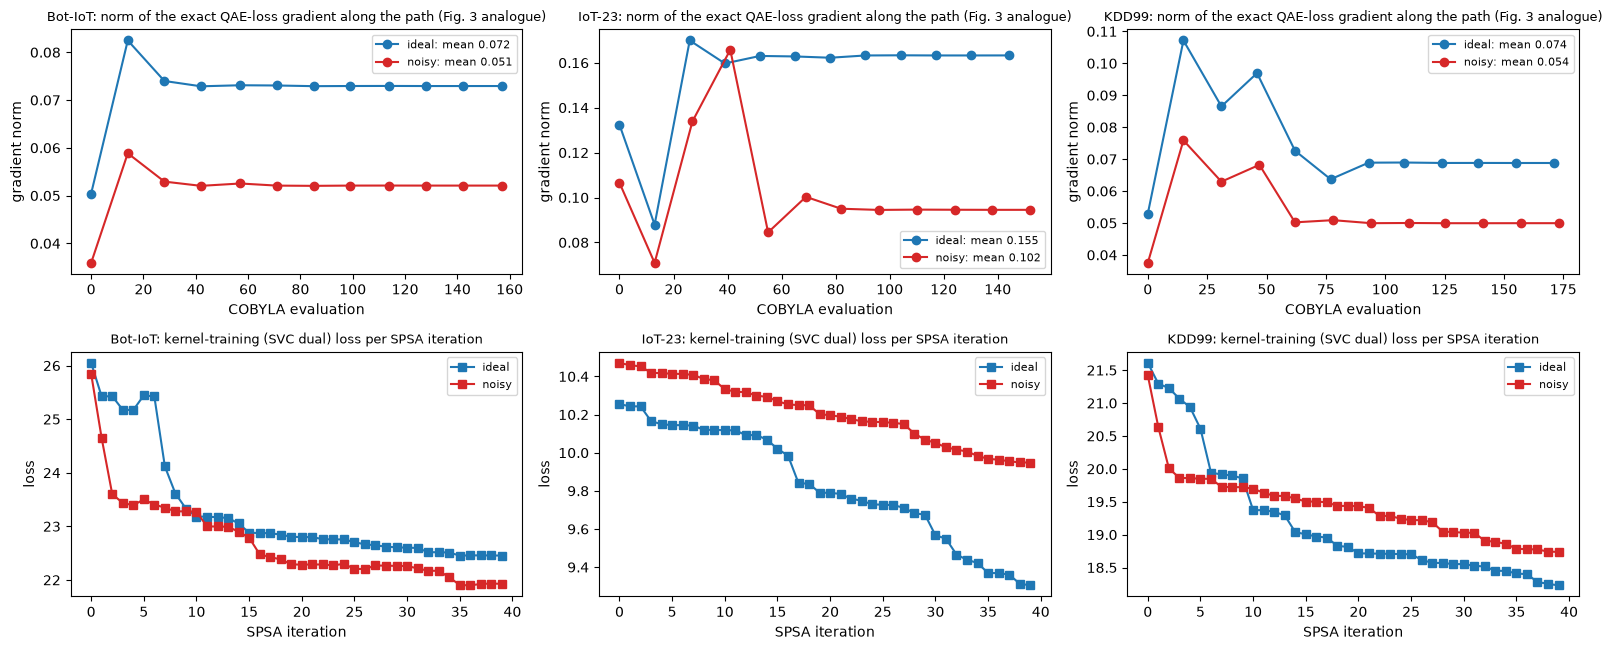

In [16]:
PAPER_T1 = {("Bot-IoT", "ideal"): (0.0191, 0.1843, 0.2590), ("IoT-23", "ideal"): (0.0171, 0.2576, 0.3244), ("KDD99", "ideal"): (0.0213, 0.2826, 0.3660),
            ("Bot-IoT", "noisy"): (0.0168, 0.2906, 0.3564), ("IoT-23", "noisy"): (0.0302, 0.1513, 0.2699), ("KDD99", "noisy"): (0.0169, 0.2644, 0.3308)}
rows = []
for (ds, cond), R in MAIN.items():
    qa = R["qae"]; mu, sd = qa["mu"], qa["sd"]
    rows.append(dict(dataset=ds, noise=cond, evals=len(mu), loss_start=mu[0], loss_end_mean_last10=mu[-10:].mean(), avg_loss_std=sd.mean(),
                     avg_lower=(mu - 1.96 * sd).mean(), avg_upper=(mu + 1.96 * sd).mean(), exact_loss_of_final_theta=qa["exact_loss_end"],
                     paper_std=PAPER_T1[(ds, cond)][0], paper_lower=PAPER_T1[(ds, cond)][1], paper_upper=PAPER_T1[(ds, cond)][2]))
T1 = pd.DataFrame(rows); display(T1.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, ds in zip(ax, DATASETS):
    for cond, c in [("ideal", "tab:blue"), ("noisy", "tab:red")]:
        qa = MAIN[(ds, cond)]["qae"]; x = np.arange(len(qa["mu"]))
        a.plot(x, qa["mu"], color=c, label=cond); a.fill_between(x, qa["mu"] - 1.96 * qa["sd"], qa["mu"] + 1.96 * qa["sd"], color=c, alpha=0.2)
    a.set_title(f"{ds}: QAE loss P(aux = 1), mean and 95 % band"); a.set_xlabel("COBYLA evaluation"); a.set_ylabel("loss"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for a, ds in zip(ax, DATASETS):
    for cond, c in [("ideal", "tab:blue"), ("noisy", "tab:red")]:
        qa = MAIN[(ds, cond)]["qae"]; cv = qa["sd"] / qa["mu"]; k = min(10, len(cv))
        a.plot(np.convolve(cv, np.ones(k) / k, mode="valid"), color=c, label=cond)
    a.set_title(f"{ds}: coefficient of variation of the batch losses (moving average)"); a.set_xlabel("COBYLA evaluation"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(16, 6.6))
for a, ds in zip(ax[0], DATASETS):
    for cond, c in [("ideal", "tab:blue"), ("noisy", "tab:red")]:
        qa = MAIN[(ds, cond)]["qae"]; g = qa["grad"]
        a.plot(qa["grad_it"], g, "o-", color=c, label=f"{cond}: mean {g.mean():.3f}")
    a.set_title(f"{ds}: norm of the exact QAE-loss gradient along the path (Fig. 3 analogue)", fontsize=9); a.set_xlabel("COBYLA evaluation"); a.set_ylabel("gradient norm"); a.legend(fontsize=8)
for a, ds in zip(ax[1], DATASETS):
    for cond, c in [("ideal", "tab:blue"), ("noisy", "tab:red")]:
        sl = MAIN[(ds, cond)]["kern"]["spsa_loss"]; a.plot(sl, "s-", color=c, label=cond)
    a.set_title(f"{ds}: kernel-training (SVC dual) loss per SPSA iteration", fontsize=9); a.set_xlabel("SPSA iteration"); a.set_ylabel("loss"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Is the quantum part doing anything? Classical baselines on the same inputs, and the kernel-training ablation

The paper's abstract speaks of "practical quantum advantage" but shows no classical comparison. Here a random forest and an
RBF-SVM are trained on (a) the padded amplitude vectors that enter the QAE and (b) the QAE's latent features that enter the
kernel, and the QSVC is compared with an **untrained** kernel (parameters at their random start) to see whether the SPSA
kernel training (the paper's "task-adaptive kernel") helps.

,dataset,run,model,inputs,test_acc,test_f1
0,Bot-IoT,ideal,"QSVC, trained kernel (this paper)",QAE latent (4 angles),0.8125,0.8101
1,Bot-IoT,ideal,RandomForest,QAE latent (4 numbers),0.8500,0.8492
2,Bot-IoT,ideal,SVC (rbf),QAE latent (4 numbers),0.7750,0.7727
3,Bot-IoT,ideal,RandomForest,amplitude vectors (32 numbers),0.9875,0.9875
4,Bot-IoT,ideal,SVC (rbf),amplitude vectors (32 numbers),0.9875,0.9875
5,Bot-IoT,ideal,"QSVC, UNTRAINED kernel (ablation)",QAE latent (4 angles),0.8625,0.8620
6,Bot-IoT,noisy,"QSVC, trained kernel (this paper)",QAE latent (4 angles),0.8000,0.7968
7,Bot-IoT,noisy,RandomForest,QAE latent (4 numbers),0.8500,0.8496
8,Bot-IoT,noisy,SVC (rbf),QAE latent (4 numbers),0.7750,0.7727
9,IoT-23,ideal,"QSVC, trained kernel (this paper)",QAE latent (4 angles),0.8250,0.8232


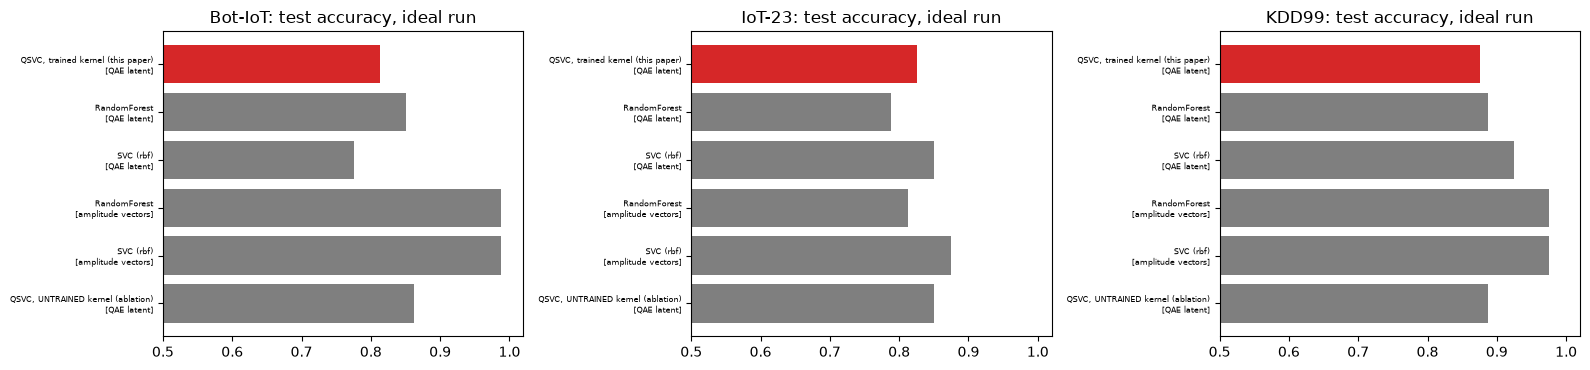

In [17]:
rows = []
for ds in DATASETS:
    for cond in ("ideal", "noisy"):
        R = MAIN[(ds, cond)]
        rows.append(dict(dataset=ds, run=cond, model="QSVC, trained kernel (this paper)", inputs="QAE latent (4 angles)", test_acc=R["kern"]["m_te"]["acc"], test_f1=R["kern"]["m_te"]["f1"]))
        for nm, v in R["base_lat"].items(): rows.append(dict(dataset=ds, run=cond, model=nm, inputs="QAE latent (4 numbers)", test_acc=v["acc"], test_f1=v["f1"]))
        if cond == "ideal":
            for nm, v in R["base_amp"].items(): rows.append(dict(dataset=ds, run=cond, model=nm, inputs=f"amplitude vectors ({2 ** R['D']['nq']} numbers)", test_acc=v["acc"], test_f1=v["f1"]))
            ks0 = kernel_stage(R["Ztr"], R["D"]["ytr"], R["Zte"], R["D"]["yte"], SEED, noisy=False, trained=False)
            rows.append(dict(dataset=ds, run=cond, model="QSVC, UNTRAINED kernel (ablation)", inputs="QAE latent (4 angles)", test_acc=ks0["m_te"]["acc"], test_f1=ks0["m_te"]["f1"]))
            MAIN[(ds, cond)]["untrained"] = ks0
BASE = pd.DataFrame(rows); display(BASE.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, ds in zip(ax, DATASETS):
    b = BASE[(BASE.dataset == ds) & (BASE.run == "ideal")]; lab = [f"{m}\n[{i.split(' (')[0]}]" for m, i in zip(b.model, b.inputs)]
    a.barh(range(len(b)), b.test_acc, color=["tab:red" if m.startswith("QSVC, trained") else "tab:gray" for m in b.model]); a.set_yticks(range(len(b))); a.set_yticklabels(lab, fontsize=6)
    a.set_xlim(0.5, 1.02); a.set_title(f"{ds}: test accuracy, ideal run"); a.invert_yaxis()
plt.tight_layout(); plt.show()

## 8. Repeating the pipeline over several seeds

A single seed on a small test set is a noisy estimate. The pipeline is repeated with different random draws of the records, splits,
initial parameters and mini-batches (`N_SEEDS` seeds for the ideal runs, the first `N_NOISY_SEEDS` of them also with noise); the table
shows mean $\pm$ standard deviation over seeds, which is what the comparison ideal versus noisy (the "implicit regularisation" claim)
has to be judged on.

In [18]:
SEEDS = [SEED + i for i in range(N_SEEDS)]; NOISY_SEEDS = SEEDS[:N_NOISY_SEEDS]
RUNS = {(ds, cond, SEED): R for (ds, cond), R in MAIN.items()}
for ds in DATASETS:
    for s in SEEDS:
        if (ds, "ideal", s) not in RUNS: RUNS[(ds, "ideal", s)] = run_pipeline(ds, s, noisy=False)
        if s in NOISY_SEEDS and (ds, "noisy", s) not in RUNS: RUNS[(ds, "noisy", s)] = run_pipeline(ds, s, noisy=True)
ms_rows = []
for (ds, cond, s), R in RUNS.items():
    k = R["kern"]
    row = dict(dataset=ds, noise=cond, seed=s, QSVC_test_acc=k["m_te"]["acc"], QSVC_test_f1=k["m_te"]["f1"], QSVC_train_acc=k["m_tr"]["acc"], gap_train_minus_test=k["m_tr"]["acc"] - k["m_te"]["acc"],
               final_QAE_loss_ideal_eval=R["qae"]["exact_loss_end"])
    for nm, v in R["base_lat"].items(): row[f"{nm} / latent"] = v["acc"]
    for nm, v in R["base_amp"].items(): row[f"{nm} / amplitudes"] = v["acc"]
    if cond == "ideal":                                                     # ablation: the same kernel with its random starting parameters (no SPSA training)
        row["QSVC_untrained_acc"] = kernel_stage(R["Ztr"], R["D"]["ytr"], R["Zte"], R["D"]["yte"], s, noisy=False, trained=False)["m_te"]["acc"]
    ms_rows.append(row)
MS = pd.DataFrame(ms_rows).sort_values(["dataset", "noise", "seed"], key=lambda c: c.map({d: i for i, d in enumerate(DATASETS)}) if c.name == "dataset" else c).reset_index(drop=True)
display(MS.round(3))
cols = ["QSVC_test_acc", "QSVC_untrained_acc", "QSVC_test_f1", "QSVC_train_acc", "gap_train_minus_test", "RandomForest / latent", "SVC (rbf) / latent", "RandomForest / amplitudes", "SVC (rbf) / amplitudes"]
agg = MS.groupby(["dataset", "noise"], sort=False)[cols].agg(["mean", "std"]).round(3)
display(agg)
print("ideal seeds:", SEEDS, "| noisy seeds:", NOISY_SEEDS)

,dataset,noise,seed,QSVC_test_acc,QSVC_test_f1,QSVC_train_acc,gap_train_minus_test,final_QAE_loss_ideal_eval,RandomForest / latent,SVC (rbf) / latent,RandomForest / amplitudes,SVC (rbf) / amplitudes,QSVC_untrained_acc
0,Bot-IoT,ideal,42,0.812,0.810,0.991,0.178,0.368,0.850,0.775,0.988,0.988,0.862
1,Bot-IoT,ideal,43,0.800,0.798,0.912,0.112,0.372,0.912,0.900,1.000,1.000,0.775
2,Bot-IoT,ideal,44,0.862,0.862,0.994,0.131,0.377,0.900,0.775,0.988,0.988,0.888
3,Bot-IoT,ideal,45,0.862,0.862,0.919,0.056,0.354,0.862,0.812,1.000,1.000,0.862
4,Bot-IoT,ideal,46,0.862,0.862,0.906,0.044,0.356,0.875,0.825,0.988,0.988,0.850
5,Bot-IoT,noisy,42,0.800,0.797,0.962,0.162,0.368,0.850,0.775,0.988,0.988,NaN
6,Bot-IoT,noisy,43,0.838,0.837,1.000,0.162,0.373,0.900,0.850,1.000,1.000,NaN
7,Bot-IoT,noisy,44,0.762,0.762,1.000,0.238,0.386,0.850,0.788,0.988,0.988,NaN
8,IoT-23,ideal,42,0.825,0.823,0.947,0.122,0.208,0.788,0.850,0.812,0.875,0.850
9,IoT-23,ideal,43,0.875,0.875,0.956,0.081,0.229,0.812,0.912,0.825,0.938,0.912


QSVC_test_acc        QSVC_untrained_acc        QSVC_test_f1        QSVC_train_acc        gap_train_minus_test        RandomForest / latent        SVC (rbf) / latent        RandomForest / amplitudes  \
                       mean    std               mean    std         mean    std           mean    std                 mean    std                  mean    std               mean    std                      mean   
dataset noise                                                                                                                                                                                                         
Bot-IoT ideal         0.840  0.031              0.847  0.043        0.839  0.032          0.944  0.044                0.104  0.055                 0.880  0.026              0.818  0.051                     0.992   
        noisy         0.800  0.038                NaN    NaN        0.799  0.038          0.987  0.022                0.188  0.043                 0.867  0.029              0.804  0.040                     0.992   
IoT-23  ideal         0.855  0.023              0.865  0.029        0.853  0.024          0.951  0.007                0.096  0.024                 0.838  0.042              0.868  0.029                     0.852   
        noisy         0.883  0.014                NaN    NaN        0.882  0.015          0.920  0.039                0.036  0.033                 0.821  0.031              0.888  0.022                     0.833   
KDD99   ideal         0.872  0.029              0.872  0.016        0.872  0.029          0.932  0.039                0.059  0.013                 0.910  0.021              0.893  0.060                     0.975   
        noisy         0.875  0.012                NaN    NaN        0.874  0.013          0.929  0.023                0.054  0.024                 0.904  0.026              0.912  0.022                     0.979   

                     SVC (rbf) / amplitudes         
                 std                   mean    std  
dataset noise                                       
Bot-IoT ideal  0.007                  0.992  0.007  
        noisy  0.007                  0.992  0.007  
IoT-23  ideal  0.035                  0.893  0.029  
        noisy  0.026                  0.904  0.031  
KDD99   ideal  0.009                  0.978  0.019  
        noisy  0.007                  0.975  0.025

ideal seeds: [42, 43, 44, 45, 46] | noisy seeds: [42, 43, 44]


### Sensitivity to the latent size $n_l$ (not given in the paper)

The paper does not say how many latent qubits it keeps. The main runs use $n_l=2$ (4 latent probabilities, a 4-qubit kernel).
The next cell repeats the **ideal** pipeline with $n_l=3$ (8 latent probabilities, an 8-qubit kernel, one trash qubit fewer) for the
same data draws, so that the reader can see how much of the result hangs on this choice.

In [19]:
def with_latent_size(nl, fn):
    """Temporarily rebuild the latent-size dependent globals (n_l, kernel qubits, kernel feature map, cached QAE models)."""
    global NL_QUBITS, NK, KFM
    saved = (NL_QUBITS, NK, KFM, dict(QAE_MODELS))
    NL_QUBITS, NK = nl, 2 ** nl; KFM = KernelFM(NK, KERNEL_REPS); QAE_MODELS.clear()
    try:
        return fn()
    finally:
        NL_QUBITS, NK, KFM = saved[0], saved[1], saved[2]; QAE_MODELS.clear(); QAE_MODELS.update(saved[3])

NL_ALT = 3
NL_SEEDS = SEEDS[:1] if FAST_MODE else SEEDS[:3]
sens = []
for ds in DATASETS:
    for s in NL_SEEDS:
        base = MAIN[(ds, "ideal")] if s == SEED else run_pipeline(ds, s, noisy=False)
        alt = with_latent_size(NL_ALT, lambda: run_pipeline(ds, s, noisy=False))
        sens.append(dict(dataset=ds, seed=s, loss_nl2=base["qae"]["exact_loss_end"], loss_nl3=alt["qae"]["exact_loss_end"], QSVC_nl2=base["kern"]["m_te"]["acc"],
                         QSVC_nl3=alt["kern"]["m_te"]["acc"], RF_latent_nl2=base["base_lat"]["RandomForest"]["acc"], RF_latent_nl3=alt["base_lat"]["RandomForest"]["acc"]))
SENS = pd.DataFrame(sens); display(SENS.round(3))
print(SENS.groupby("dataset", sort=False)[["QSVC_nl2", "QSVC_nl3", "RF_latent_nl2", "RF_latent_nl3"]].mean().round(3))
print("n_l restored to", NL_QUBITS, "| kernel qubits", NK)

,dataset,seed,loss_nl2,loss_nl3,QSVC_nl2,QSVC_nl3,RF_latent_nl2,RF_latent_nl3
0,Bot-IoT,42,0.368,0.281,0.812,0.862,0.850,0.938
1,Bot-IoT,43,0.372,0.275,0.800,0.850,0.912,0.938
2,Bot-IoT,44,0.377,0.297,0.875,0.900,0.900,0.950
3,IoT-23,42,0.208,0.115,0.825,0.862,0.788,0.800
4,IoT-23,43,0.229,0.085,0.888,0.888,0.812,0.825
5,IoT-23,44,0.178,0.091,0.875,0.875,0.850,0.850
6,KDD99,42,0.312,0.265,0.875,0.838,0.888,0.988
7,KDD99,43,0.317,0.298,0.900,0.938,0.900,0.988
8,KDD99,44,0.346,0.258,0.838,0.912,0.900,0.925


         QSVC_nl2  QSVC_nl3  RF_latent_nl2  RF_latent_nl3
dataset                                                  
Bot-IoT     0.829     0.871          0.888          0.942
IoT-23      0.862     0.875          0.817          0.825
KDD99       0.871     0.896          0.896          0.967
n_l restored to 2 | kernel qubits 4


## 9. The hardware experiment (Table III): a calibration-based emulation of `ibm_fez`, and the real-device cell

The paper ran a reduced version on the 156-qubit IBM Quantum device `ibm_fez` (Bot-IoT and IoT-23, a few records). Real hardware needs an
IBM Quantum account, so that cell at the end is **skipped unless `IBM_TOKEN` is set**. As a stand-in, the first cell below uses
`FakeFez` from `qiskit_ibm_runtime.fake_provider`, which carries a snapshot of the device's calibration data (gate errors, readout errors,
coupling map, native gates). The compute-uncompute kernel circuit is transpiled for that device (native gates `cz`, `sx`, `rz`,
routing on the heavy-hex coupling map) and sampled with 1024 shots in an Aer simulation of its noise. The **quantum kernel stage** is
therefore emulated on device-like noise (training Gram matrix and test-versus-train entries are all measured circuits); the QAE
latent features come from the ideal run, because the SWAP-test circuits are too slow to emulate on the full 156-qubit noise model.
It is a reduced run (`FEZ_N_TRAIN` / `FEZ_N_TEST` records) like the paper's, so one record moves the accuracy by many points. This cell
runs only when `FAST_MODE = False` (the noise-model set-up alone takes a few minutes).

In [20]:
FEZ_ROWS = []
if RUN_FAKE_FEZ:
    from qiskit_ibm_runtime.fake_provider import FakeFez
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    t0 = time.time(); fez = FakeFez(); fez_sim = AerSimulator.from_backend(fez)
    fez_cu = KFM.cu.copy(); fez_cu.measure_all()
    fez_t = generate_preset_pass_manager(optimization_level=1, backend=fez, seed_transpiler=SEED).run(fez_cu)
    used = sorted({fez_t.find_bit(q).index for inst in fez_t.data for q in inst.qubits})
    print(f"FakeFez set-up {time.time() - t0:.0f} s | kernel circuit on physical qubits {used}: depth {fez_t.depth()}, gates {dict(fez_t.count_ops())}")

    def fez_entries(A, B, ph):
        binds = {}
        for i in range(KFM.nk):
            binds[KFM.zA[i]] = list(A[:, i]); binds[KFM.zB[i]] = list(B[:, i])
        for i in range(2 * KFM.nk): binds[KFM.phi[i]] = [float(ph[i])] * len(A)
        res = fez_sim.run(fez_t, parameter_binds=[binds], shots=FEZ_SHOTS).result()
        return np.array([res.get_counts(i).get("0" * KFM.nk, 0) / FEZ_SHOTS for i in range(len(A))])

    for ds in ["Bot-IoT", "IoT-23"]:
        t0 = time.time(); R = MAIN[(ds, "ideal")]; ks, D = R["kern"], R["D"]
        itr = np.concatenate([np.where(D["ytr"] == c)[0][:FEZ_N_TRAIN // 2] for c in (0, 1)]); ite = np.concatenate([np.where(D["yte"] == c)[0][:FEZ_N_TEST // 2] for c in (0, 1)])
        A, T = ks["Atr"][itr], ks["Ate"][ite]; ph = ks["phi"]
        iu = np.triu_indices(len(A), 1); v = fez_entries(A[iu[0]], A[iu[1]], ph)
        Kt = np.eye(len(A)); Kt[iu] = v; Kt[(iu[1], iu[0])] = v
        w, U = np.linalg.eigh(Kt); Kt = (U * np.clip(w, 0, None)) @ U.T; dd = np.sqrt(np.diag(Kt)); Kt = Kt / np.outer(dd, dd)
        ia, ib = np.meshgrid(np.arange(len(T)), np.arange(len(A)), indexing="ij")
        Ke = fez_entries(T[ia.ravel()], A[ib.ravel()], ph).reshape(len(T), len(A))
        clf = SVC(kernel="precomputed", C=ks["C"]).fit(Kt, D["ytr"][itr]); p_fez = clf.predict(Ke)
        kern = FastKernel(KFM); kern.assign_training_parameters(ph); clf0 = SVC(kernel="precomputed", C=ks["C"]).fit(kern.evaluate(A), D["ytr"][itr])
        p_ideal = clf0.predict(kern.evaluate(T, A)); m = metrics_dict(D["yte"][ite], p_fez)
        FEZ_ROWS.append(dict(dataset=ds, n_train=len(A), n_test=len(T), acc_fakefez=m["acc"], prec=m["prec"], rec=m["rec"], f1=m["f1"], acc_exact_kernel=accuracy_score(D["yte"][ite], p_ideal),
                             mean_abs_kernel_error=float(np.abs(Ke - kern.evaluate(T, A)).mean()), seconds=time.time() - t0,
                             paper_acc=0.8333 if ds == "Bot-IoT" else 0.8437))
        print(FEZ_ROWS[-1], flush=True)
    display(pd.DataFrame(FEZ_ROWS).round(4))
else:
    print("RUN_FAKE_FEZ is False (FAST_MODE): the ibm_fez emulation is skipped.")

FakeFez set-up 28 s | kernel circuit on physical qubits [0, 1, 2, 3]: depth 139, gates {'rz': 164, 'sx': 72, 'cz': 22, 'measure': 4, 'barrier': 1}


{'dataset': 'Bot-IoT', 'n_train': 12, 'n_test': 6, 'acc_fakefez': 0.6666666666666666, 'prec': 0.7999999999999999, 'rec': 0.6666666666666666, 'f1': 0.625, 'acc_exact_kernel': 0.6666666666666666, 'mean_abs_kernel_error': 0.013345892024896484, 'seconds': 31.35600972175598, 'paper_acc': 0.8333}


{'dataset': 'IoT-23', 'n_train': 12, 'n_test': 6, 'acc_fakefez': 0.6666666666666666, 'prec': 0.6666666666666666, 'rec': 0.6666666666666666, 'f1': 0.6666666666666666, 'acc_exact_kernel': 0.6666666666666666, 'mean_abs_kernel_error': 0.07174128508199241, 'seconds': 25.666146993637085, 'paper_acc': 0.8437}


,dataset,n_train,n_test,acc_fakefez,prec,rec,f1,acc_exact_kernel,mean_abs_kernel_error,seconds,paper_acc
0,Bot-IoT,12,6,0.6667,0.8000,0.6667,0.6250,0.6667,0.0133,31.3560,0.8333
1,IoT-23,12,6,0.6667,0.6667,0.6667,0.6667,0.6667,0.0717,25.6661,0.8437


In [21]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    svc = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = svc.backend("ibm_fez")
    ds = DATASETS[0]; R = MAIN[(ds, "ideal")]; ks = R["kern"]; n_tr, n_te = 24, 12                      # tiny, as in the paper ("reduced samples")
    ia = np.arange(n_te)[:, None].repeat(n_tr, 1).ravel(); ib = np.tile(np.arange(n_tr), n_te)
    phi_v = ks["phi"]; pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
    cu = KFM.cu.copy(); cu.measure_all()
    circs = [pm.run(cu.assign_parameters({**dict(zip(KFM.zA, ks["Ate"][a])), **dict(zip(KFM.zB, ks["Atr"][b])), **dict(zip(KFM.phi, phi_v))})) for a, b in zip(ia, ib)]
    job = SamplerV2(mode=backend).run(circs, shots=1024); res = job.result()
    k = np.array([r.data.meas.get_counts().get("0" * KFM.nk, 0) / 1024 for r in res]).reshape(n_te, n_tr)
    clf = SVC(kernel="precomputed", C=ks["C"]).fit(ks["Ktr"][:n_tr, :n_tr], R["D"]["ytr"][:n_tr])
    print("hardware accuracy on", n_te, "test records:", accuracy_score(R["D"]["yte"][:n_te], clf.predict(k)))
else:
    print("IBM_TOKEN is empty -> the real-hardware cell is skipped. Table III (ibm_fez) cannot be checked here.")

IBM_TOKEN is empty -> the real-hardware cell is skipped. Table III (ibm_fez) cannot be checked here.


## 10. Side by side with the paper, claim by claim

Verdicts use the project rule: **reproduced** when within 2 accuracy points (0.02 F1) of the paper, otherwise **not reached** or
**exceeded** with the gap, **cannot be checked** when the quantity cannot be measured here. Remember that the notebook's test sets
contain only a few dozen records.

In [22]:
rows = []
for (ds, cond), R in MAIN.items():
    me, name = R["kern"]["m_te"], "Table II " + ("noisy" if cond == "noisy" else "ideal")
    p = PAPER_T2[(ds, cond)]
    for metric, pv, ov in [("test accuracy", p[1], me["acc"]), ("test weighted F1", p[7], me["f1"]), ("test weighted precision", p[3], me["prec"]), ("test weighted recall", p[5], me["rec"])]:
        rows.append(dict(source=name, item=ds, metric=metric, paper=pv, notebook=round(ov, 4), gap=round(ov - pv, 4), verdict=verdict(pv, ov)))
for (ds, cond), R in MAIN.items():
    st = T1[(T1.dataset == ds) & (T1.noise == cond)].iloc[0]
    rows.append(dict(source="Table I " + cond, item=ds, metric="avg loss std", paper=PAPER_T1[(ds, cond)][0], notebook=round(st.avg_loss_std, 4), gap=round(st.avg_loss_std - PAPER_T1[(ds, cond)][0], 4), verdict=verdict(PAPER_T1[(ds, cond)][0], st.avg_loss_std, 0.01)))
cmp_df = pd.DataFrame(rows); display(cmp_df)
print(cmp_df.groupby(["source", "metric"])["verdict"].value_counts().unstack(fill_value=0))

,source,item,metric,paper,notebook,gap,verdict
0,Table II ideal,Bot-IoT,test accuracy,0.9242,0.8125,-0.1117,not reached
1,Table II ideal,Bot-IoT,test weighted F1,0.9294,0.8101,-0.1193,not reached
2,Table II ideal,Bot-IoT,test weighted precision,0.9247,0.8292,-0.0955,not reached
3,Table II ideal,Bot-IoT,test weighted recall,0.9242,0.8125,-0.1117,not reached
4,Table II ideal,IoT-23,test accuracy,0.9950,0.8250,-0.1700,not reached
5,Table II ideal,IoT-23,test weighted F1,0.9268,0.8232,-0.1036,not reached
6,Table II ideal,IoT-23,test weighted precision,0.9650,0.8385,-0.1265,not reached
7,Table II ideal,IoT-23,test weighted recall,0.9500,0.8250,-0.1250,not reached
8,Table II ideal,KDD99,test accuracy,0.9766,0.8750,-0.1016,not reached
9,Table II ideal,KDD99,test weighted F1,0.9766,0.8749,-0.1017,not reached


verdict                                 not reached  reproduced
source         metric                                          
Table I ideal  avg loss std                       1           2
Table I noisy  avg loss std                       2           1
Table II ideal test accuracy                      3           0
               test weighted F1                   3           0
               test weighted precision            3           0
               test weighted recall               3           0
Table II noisy test accuracy                      3           0
               test weighted F1                   3           0
               test weighted precision            3           0
               test weighted recall               3           0


In [23]:
te = lambda ds, c: MAIN[(ds, c)]["kern"]["m_te"]["acc"]
fin = lambda ds, c: float(MAIN[(ds, c)]["qae"]["mu"][-10:].mean())
def mcol(ds, cond, col, seeds=None):                       # mean over the seeds that were run for this condition
    m = MS[(MS.dataset == ds) & (MS.noise == cond)]
    if seeds is not None: m = m[m.seed.isin(seeds)]
    return float(m[col].mean())
claims = []
def claim(text, notebook, verdict_text): claims.append(dict(claim=text, notebook=notebook, verdict=verdict_text))

acc_i = {ds: mcol(ds, "ideal", "QSVC_test_acc") for ds in DATASETS}; acc_n = {ds: mcol(ds, "noisy", "QSVC_test_acc") for ds in DATASETS}
ok = [acc_i[ds] >= 0.92 for ds in DATASETS]
claim(f"Ideal simulator: test accuracy above 92 % on all three data sets (Table II); mean over {len(SEEDS)} seeds",
      ", ".join(f"{ds} {acc_i[ds]:.3f} (seed 42: {te(ds, 'ideal'):.3f})" for ds in DATASETS), "reproduced" if all(ok) else f"not reached on {[d for d, o in zip(DATASETS, ok) if not o]} (gaps {', '.join(f'{acc_i[d] - 0.92:+.3f}' for d in DATASETS)} to 0.92)")
ok = [acc_n[ds] >= 0.95 for ds in DATASETS]
claim(f"Depolarizing noise: accuracy above 95 % for most data sets (Table II); mean over {len(NOISY_SEEDS)} seed(s)", ", ".join(f"{ds} {acc_n[ds]:.3f} (seed 42: {te(ds, 'noisy'):.3f})" for ds in DATASETS),
      "reproduced" if sum(ok) >= 2 else f"not reached (only {sum(ok)} of 3 data sets)")
d = {ds: mcol(ds, "noisy", "QSVC_test_acc", NOISY_SEEDS) - mcol(ds, "ideal", "QSVC_test_acc", NOISY_SEEDS) for ds in DATASETS}
n_better, n_worse = sum(v > 0.02 for v in d.values()), sum(v < -0.02 for v in d.values())
claim(f"Noise acts as implicit regularisation: noisy test accuracy better than the ideal one (paper: better on Bot-IoT and KDD99, worse on IoT-23); mean over {len(NOISY_SEEDS)} seed(s)",
      ", ".join(f"{ds} {v:+.3f}" for ds, v in d.items()), "reproduced" if n_better >= 2 else ("partly" if n_better == 1 and n_worse == 0 else f"not supported: {n_better} data set(s) better, {n_worse} worse by more than 0.02; differences are of the size of the seed-to-seed scatter"))
g = {ds: (mcol(ds, "ideal", "gap_train_minus_test", NOISY_SEEDS), mcol(ds, "noisy", "gap_train_minus_test", NOISY_SEEDS)) for ds in DATASETS}
claim(f"Generalisation gap (train - test accuracy) is smaller with noise; mean over {len(NOISY_SEEDS)} seed(s)", ", ".join(f"{ds} ideal {a:+.3f} / noisy {b:+.3f}" for ds, (a, b) in g.items()),
      "reproduced" if sum(b < a - 0.01 for a, b in g.values()) >= 2 else "not reproduced")
lo, ln = fin("Bot-IoT", "ideal"), fin("Bot-IoT", "noisy")
claim("Bot-IoT QAE loss floor: about 0.20 ideal, about 0.30 noisy (Fig. 2)", f"final-10 mean batch loss ideal {lo:.3f}, noisy {ln:.3f}",
      f"ideal {'reproduced' if abs(lo - 0.20) <= 0.05 else f'not reached (higher by {lo - 0.20:.2f})'}, noisy {'reproduced' if abs(ln - 0.30) <= 0.05 else f'not reached (higher by {ln - 0.30:.2f})'} (tolerance 0.05); noisy loss above ideal loss: {ln > lo}")
claim("Training loss decreases consistently (Fig. 2)", ", ".join(f"{ds} {MAIN[(ds, 'ideal')]['qae']['exact_loss_start']:.3f}->{MAIN[(ds, 'ideal')]['qae']['exact_loss_end']:.3f}" for ds in DATASETS),
      "reproduced" if all(MAIN[(ds, 'ideal')]['qae']['exact_loss_end'] < MAIN[(ds, 'ideal')]['qae']['exact_loss_start'] - 0.02 for ds in DATASETS) else "not reproduced")
ab = {ds: mcol(ds, "ideal", "QSVC_test_acc") - mcol(ds, "ideal", "QSVC_untrained_acc") for ds in DATASETS}
claim(f"Kernel training improves separability (trained minus untrained kernel, test accuracy, mean over {len(SEEDS)} seeds)", ", ".join(f"{ds} {v:+.3f}" for ds, v in ab.items()),
      "reproduced" if sum(v > 0.02 for v in ab.values()) >= 2 else ("no measurable effect (within 2 points)" if all(abs(v) <= 0.02 for v in ab.values()) else "not reproduced (training does not help on most data sets)"))
bl = {ds: max(mcol(ds, "ideal", "RandomForest / latent"), mcol(ds, "ideal", "SVC (rbf) / latent")) for ds in DATASETS}
ba = {ds: max(mcol(ds, "ideal", "RandomForest / amplitudes"), mcol(ds, "ideal", "SVC (rbf) / amplitudes")) for ds in DATASETS}
claim("'Practical quantum advantage': QSVC beats classical models (no such comparison in the paper); mean over seeds, best of RF / SVC",
      ", ".join(f"{ds}: QSVC {acc_i[ds]:.3f} | classical on latent {bl[ds]:.3f} | classical on amplitudes {ba[ds]:.3f}" for ds in DATASETS),
      "supported" if all(acc_i[ds] > max(bl[ds], ba[ds]) + 0.02 for ds in DATASETS) else "not supported: classical models on the same inputs are as good as or better than the QSVC")
for ds, theirs_acc in [("KDD99", 0.9748), ("IoT-23", 0.8253)]:
    claim(f"Table IV: beats QAE + one-class SVM of Hdaib et al. on {ds} ({theirs_acc:.4f}; their numbers quoted, other protocol)",
          f"ideal {acc_i[ds]:.3f}, noisy {acc_n[ds]:.3f} (seed means)", "consistent with the claim" if min(acc_i[ds], acc_n[ds]) > theirs_acc else ("partly" if max(acc_i[ds], acc_n[ds]) > theirs_acc else "not reached"))
gm = {ds: (MAIN[(ds, "ideal")]["qae"]["grad"].mean(), MAIN[(ds, "noisy")]["qae"]["grad"].mean()) for ds in DATASETS}
claim("Fig. 3: Bot-IoT and KDD99 show higher gradient magnitudes with noise, IoT-23 smoother (exact parameter-shift gradient norm, mean along the path)",
      ", ".join(f"{ds} ideal {a:.3f} / noisy {b:.3f}" for ds, (a, b) in gm.items()),
      "Bot-IoT " + ("reproduced" if gm["Bot-IoT"][1] > gm["Bot-IoT"][0] else "not reproduced") + ", KDD99 " + ("reproduced" if gm["KDD99"][1] > gm["KDD99"][0] else "not reproduced")
      + "; IoT-23 smoother: " + ("yes" if gm["IoT-23"][1] <= gm["IoT-23"][0] else "no") + " (the paper's loss gradient may include shot noise; trajectories differ)")
cvm = {ds: (np.mean(MAIN[(ds, "ideal")]["qae"]["sd"] / MAIN[(ds, "ideal")]["qae"]["mu"]), np.mean(MAIN[(ds, "noisy")]["qae"]["sd"] / MAIN[(ds, "noisy")]["qae"]["mu"])) for ds in DATASETS}
claim("Fig. 4: lower coefficient of variation of the loss in most noisy cases, especially KDD99", ", ".join(f"{ds} ideal {a:.3f} / noisy {b:.3f}" for ds, (a, b) in cvm.items()),
      "reproduced" if sum(b < a for a, b in cvm.values()) >= 2 else "not reproduced")
if FEZ_ROWS:
    claim("Table III: 83.3 % (Bot-IoT) / 84.4 % (IoT-23) on IBM ibm_fez hardware", "; ".join(f"{r['dataset']} {r['acc_fakefez']:.3f} on {r['n_test']} test records (FakeFez emulation of the kernel stage; exact kernel {r['acc_exact_kernel']:.3f})" for r in FEZ_ROWS),
          "cannot be checked on real hardware; emulation: " + ", ".join(f"{r['dataset']} {verdict(r['paper_acc'], r['acc_fakefez'], 0.1)}" for r in FEZ_ROWS) + " (one record of 6 = 0.167; the exact kernel gives the same accuracy, so device noise is not what limits it)")
else:
    claim("Table III: 83.3 % / 84.4 % on IBM ibm_fez hardware", "no hardware access here; emulation skipped in FAST_MODE", "cannot be checked")
claim("Table II run times (8.4e4 to 1.6e5 s)", "minutes on a laptop with far smaller samples", "cannot be checked")
display(pd.DataFrame(claims))
print(f"total notebook runtime: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE = {FAST_MODE}, N_PER_CLASS = {N_PER_CLASS})")

,claim,notebook,verdict
0,Ideal simulator: test accuracy above 92 % on a...,"Bot-IoT 0.840 (seed 42: 0.812), IoT-23 0.855 (...","not reached on ['Bot-IoT', 'IoT-23', 'KDD99'] ..."
1,Depolarizing noise: accuracy above 95 % for mo...,"Bot-IoT 0.800 (seed 42: 0.800), IoT-23 0.883 (...",not reached (only 0 of 3 data sets)
2,Noise acts as implicit regularisation: noisy t...,"Bot-IoT -0.025, IoT-23 +0.025, KDD99 -0.004","not supported: 1 data set(s) better, 1 worse b..."
3,Generalisation gap (train - test accuracy) is ...,"Bot-IoT ideal +0.141 / noisy +0.188, IoT-23 id...",not reproduced
4,"Bot-IoT QAE loss floor: about 0.20 ideal, abou...","final-10 mean batch loss ideal 0.367, noisy 0.396","ideal not reached (higher by 0.17), noisy not ..."
5,Training loss decreases consistently (Fig. 2),"Bot-IoT 0.435->0.368, IoT-23 0.395->0.208, KDD...",reproduced
6,Kernel training improves separability (trained...,"Bot-IoT -0.007, IoT-23 -0.010, KDD99 +0.000",no measurable effect (within 2 points)
7,'Practical quantum advantage': QSVC beats clas...,Bot-IoT: QSVC 0.840 | classical on latent 0.88...,not supported: classical models on the same in...
8,Table IV: beats QAE + one-class SVM of Hdaib e...,"ideal 0.872, noisy 0.875 (seed means)",not reached
9,Table IV: beats QAE + one-class SVM of Hdaib e...,"ideal 0.855, noisy 0.883 (seed means)",consistent with the claim


total notebook runtime: 96.2 min (FAST_MODE = False, N_PER_CLASS = 200)


## 11. Reading the paper critically

*(The numbers below are those of the committed full run, `FAST_MODE = False`; they are printed in the tables above.)*

* **The paper's accuracies were not reached.** With 200 records per class, five seeds and the budgets of the config cell, the
  ideal QAE-QSVC reaches a mean test accuracy of about 0.84 (Bot-IoT), 0.86 (IoT-23) and 0.87 (KDD99), against 0.92, 0.995 and 0.977 in the
  paper's Table II; with depolarizing noise about 0.80, 0.88 and 0.88 against 0.95, 0.97 and 0.98. The paper omits $n_l$, the number of
  repetitions, sample sizes, the split, batch sizes, optimiser budgets, the kernel feature map and the noise strengths, so a gap does not
  prove the paper wrong; but it shows that the headline numbers are not a property of "QAE + trainable kernel + QSVC" as such.
* **No classical baseline in the paper, and it matters.** The abstract claims "practical quantum advantage", but the only comparison is
  with another quantum method whose numbers are quoted from a different protocol. Here a random forest and an RBF-SVM on the *same*
  amplitude vectors reach about 0.99 (Bot-IoT) and 0.98 (KDD99) and are on par with the QSVC on IoT-23; on the QAE's 4 latent numbers the
  classical models are about as good as the QSVC. The quantum part is not where the accuracy comes from, and "advantage" is not
  demonstrated.
* **The autoencoder is a lossy 4-number summary.** Compressing 16 or 32 amplitudes to the probabilities of 2 latent qubits throws information away
  (the QAE loss only falls to about 0.37, 0.21 and 0.31, against 0.22, 0.29 and 0.32 implied by the paper's Table I for the same quantity);
  the sensitivity table shows that 3 latent qubits help the QSVC a little (about +0.01 to +0.04) and the classical models on the latent features more on Bot-IoT and KDD99. The QAE is
  trained without labels; whatever discriminates attack from normal comes from the latent distribution, the kernel and the SVM.
* **The trainable kernel did not help measurably.** The ablation with the untrained (random-start) kernel, repeated over five seeds, shows mean
  differences of -0.01 to 0.00 in test accuracy, well inside the seed scatter: SPSA with a few dozen iterations on a small subset adapts
  eight rotation angles of a ZZ feature map only slightly.
* **Noise as "implicit regularisation".** The paper's evidence is a handful of accuracy differences between single ideal and noisy runs.
  Over three seeds the notebook finds differences of about $\pm0.03$, of the size of the seed-to-seed scatter, with no consistent sign and no
  smaller generalisation gap; the exact noisy simulation (depolarizing, $p_1=10^{-3}$, $p_2=10^{-2}$) changes the QAE loss floor and the
  kernel values only mildly. A regularisation claim would need noise sweeps, many seeds and confidence intervals.
* **Hardware.** The `FakeFez` emulation classifies only 6 test records (one record = 0.167 accuracy); it gives 0.667 for both data sets, and the
  exact kernel gives the same, so device noise is not what limits it. With so few records the paper's 83 % and 84 % cannot be
  distinguished from chance by any test. The paper gives no classical or random-guess reference on those records either.
* **Amplitude encoding discards the scale.** Z-score plus L2 normalisation keeps only the direction of a record; very long and very short flows with
  the same shape become identical. It is what makes the encoding possible, but it is a modelling decision with consequences.
* **Table II timings** of 1e5 seconds for a few hundred records point to a shot-based, unoptimised simulation; the exact-probability simulation here needs
  minutes, so the times say nothing about quantum speed.

## 12. Exercises

1. Set `NL_QUBITS = 3` (8 latent probabilities, 8 kernel qubits). How do the QAE loss, the latent scatter plots and the QSVC accuracy change? Compare with the sensitivity table.
2. Replace the QAE by a plain random orthogonal matrix (`theta` random, no training). Does the QSVC accuracy fall? What does that tell you about the autoencoder's contribution?
3. Sweep `P2_ERR` over `[0, 0.005, 0.01, 0.02, 0.05]`. Plot the test accuracy against the noise strength for several seeds and decide whether the paper's "implicit regularisation" survives error bars.
4. Train the kernel directly on the 16 or 32 amplitudes (a 5-qubit kernel) without the QAE. Is the autoencoder compression useful or harmful?
5. Replace the exact probabilities by `SHOTS = 1024` sampling in the SWAP test and the kernel. How does the loss uncertainty $\sigma$ in Table I change, and which part of it is shot noise versus mini-batch noise?